In [ ]:
# ==============================================================================
# Purpose:
#   Make FGSEA Hallmark heatmaps (NES) with significance stars from padj
#   - Stage-contrast within race (NHW-only, NHB-only): selected rows (main) + remaining rows (supp)
#   - Race-contrast within stage (HRL/DCIS/BC): selected rows (main) + remaining rows (supp)
# ==============================================================================

# Header

In [1]:
from utils import *

In [2]:
sc.settings.set_figure_params(dpi=600, dpi_save=600)  # 600 dpi for publication
sc.settings.figdir = "plots/Figure1"

rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none',    # Keep SVG text as font
    'font.size': 6,            # Main font size (5–7pt recommended)
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    'figure.dpi': 600,

    # --- Nature Immunology-style axes/ticks ---
    'axes.linewidth': 0.5,          # Axis lines: 0.5 pt
    'xtick.major.width': 0.5,        # Major tick lines
    'ytick.major.width': 0.5,
    'xtick.minor.width': 0.5,
    'ytick.minor.width': 0.5,
    'lines.linewidth': 0.7,          # Plot/data lines
    'axes.grid': False,              # No grid lines

    # --- Ticks on all sides ---
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.top': False,
    'xtick.bottom': False,
    'ytick.left': True,
    'ytick.right': False,


    # --- Tick label padding (minimal) ---
    'xtick.major.pad': 0,
    'ytick.major.pad': 0,

    # ---- Thin lines for Nature Immunology style ----
    'lines.linewidth': 0.5,     # General line width (default: 1.5)
    'patch.linewidth': 0.5,     # Outline for violin/bars (default: 1.0)
    
})

# plt.rcParams['axes.grid'] = False      # Extra guarantee, if using seaborn
# sns.set_style("white")                 # Removes upper/right axes and grid

# -- Scanpy vector-friendly mode --
sc.settings._vector_friendly = True

In [3]:
os.chdir('../')

In [4]:
Cell_stress           = ["UV RESPONSE UP", "UV RESPONSE DN", "UNFOLDED PROTEIN RESPONSE",
                           "REACTIVE OXYGEN SPECIES PATHWAY", "P53 PATHWAY", "HYPOXIA",
                           "G2M CHECKPOINT", "E2F TARGETS", "DNA REPAIR", "APOPTOSIS"]
Inflammation          = ["TNFA SIGNALING VIA NFKB", "INTERFERON GAMMA RESPONSE", "INTERFERON ALPHA RESPONSE",
                           "IL6 JAK STAT3 SIGNALING", "IL2 STAT5 SIGNALING", "INFLAMMATORY RESPONSE",
                           "COMPLEMENT", "ALLOGRAFT REJECTION"]
Cell_cycle_metabolism = ["PROTEIN SECRETION", "PEROXISOME", "OXIDATIVE PHOSPHORYLATION",
                           "MTORC1 SIGNALING", "GLYCOLYSIS", "FATTY ACID METABOLISM", "ADIPOGENESIS"]
Cancer                = ["TGF BETA SIGNALING", "PI3K AKT MTOR SIGNALING", "MYC TARGETS V2",
                           "MYC TARGETS V1", "MITOTIC SPINDLE", "KRAS SIGNALING UP",
                           "KRAS SIGNALING DN", "ESTROGEN RESPONSE EARLY", "ESTROGEN RESPONSE LATE",
                           "EPITHELIAL MESENCHYMAL TRANSITION", "APICAL SURFACE", "APICAL JUNCTION",
                           "ANDROGEN RESPONSE"]
Miscellaneous         = ["XENOBIOTIC METABOLISM", "WNT BETA CATENIN SIGNALING", "SPERMATOGENESIS",
                           "PANCREAS BETA CELLS", "NOTCH SIGNALING", "MYOGENESIS",
                           "HEME METABOLISM", "HEDGEHOG SIGNALING", "COAGULATION",
                           "CHOLESTEROL HOMEOSTASIS", "BILE ACID METABOLISM", "ANGIOGENESIS"]

pathways_ordered = Cell_stress + Inflammation + Cell_cycle_metabolism + Cancer + Miscellaneous

In [5]:
cells_group = {
'B' :    ['Naive B','Mature B','Memory B','Plasmablast'],
'T' :   ['Naive CD4T','Central Memory CD4T','Effector Memory CD4T','Cytotoxic CD4T','Treg',
         'Naive CD8T','Central Memory CD8T','Effector Memory CD8T',
         'Double Negative T','γδ T','MAIT'],
'DC' :    ['cDC1','cDC2','pDC'],
'Mono' :    ['Classical Monocyte','Intermediate Monocyte','Nonclassical Monocyte','Cytotoxic Monocyte'],
'NK' :    ['CD56-dim NK','CD56-bright NK','Proliferating NK']
}


cells_ordered = cells_group['B'] + cells_group['T'] + cells_group['DC'] + cells_group['Mono'] + cells_group['NK']

# By Disease State

## Load data

In [6]:
dep = pd.read_csv(
    'data/07RRE_pb_deg_fgsea/fgseaHallmark_BCvsDCISvsHRL_celltypelevel3_EachRaceGroup.tsv',
    sep='\s+'
)
dep

<>:3: SyntaxWarning: invalid escape sequence '\s'
<>:3: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_804185/1943085979.py:3: SyntaxWarning: invalid escape sequence '\s'
  sep='\s+'


,pathway,pval,padj,log2err,ES,NES,size,leadingEdge,celltype,gmt,subgroup
1,ADIPOGENESIS,0.062508,0.229247,0.287805,0.305659,1.254808,141,"ACADM, SQOR, AK2, IDH1, UCP2, MRPL15, STAT5A, ...",Naive B,h.all,DCIS_vs_HRL_NHW
2,ALLOGRAFT REJECTION,0.883096,0.998305,0.040576,-0.216913,-0.812422,115,"HIF1A, LYN, ABCE1, SRGN, BCL10, EIF3A, SOCS1, ...",Naive B,h.all,DCIS_vs_HRL_NHW
3,ANDROGEN RESPONSE,0.270588,0.550314,0.104344,-0.322604,-1.117041,66,"INSIG1, FKBP5, VAPA, SAT1, ACSL3, STK39, HERC3...",Naive B,h.all,DCIS_vs_HRL_NHW
4,ANGIOGENESIS,0.908918,0.998305,0.047639,-0.299846,-0.626898,8,"LRPAP1, PTK2, APP, PF4",Naive B,h.all,DCIS_vs_HRL_NHW
5,APICAL JUNCTION,0.016014,0.100091,0.352488,0.377894,1.402143,78,"STX4, ICAM2, SHC1, MVD, IKBKG, PIK3CB, VCL, PK...",Naive B,h.all,DCIS_vs_HRL_NHW
...,...,...,...,...,...,...,...,...,...,...,...
7430,TNFA SIGNALING VIA NFKB,0.000033,0.000809,0.557332,0.603637,2.086561,35,"NFKBIA, JUNB, JUN, PPP1R15A, GADD45B, FOS, NR4...",Proliferating NK,h.all,BC_vs_HRL_NHB
7431,UNFOLDED PROTEIN RESPONSE,0.911722,0.955966,0.035015,-0.250308,-0.648887,20,"YWHAZ, CKS1B, BANF1",Proliferating NK,h.all,BC_vs_HRL_NHB
7432,UV RESPONSE DN,0.002799,0.027432,0.431708,-0.732582,-1.775443,14,"CELF2, AKT3, ATRX, TGFBR3, ADD3, NR3C1, RUNX1,...",Proliferating NK,h.all,BC_vs_HRL_NHB
7433,UV RESPONSE UP,0.012614,0.061810,0.380730,0.540576,1.679581,22,"NFKBIA, JUNB, FOS, AP2S1, ATP6V1F, ARRB2, PSMC...",Proliferating NK,h.all,BC_vs_HRL_NHB


## Export to Supp Table

In [7]:
dft = dep[['subgroup','celltype','pathway','NES','pval','padj']]

dft.columns = ['comparison group', 'cell type','pathway','NES','P value','Padj']

dft

,comparison group,cell type,pathway,NES,P value,Padj
1,DCIS_vs_HRL_NHW,Naive B,ADIPOGENESIS,1.254808,0.062508,0.229247
2,DCIS_vs_HRL_NHW,Naive B,ALLOGRAFT REJECTION,-0.812422,0.883096,0.998305
3,DCIS_vs_HRL_NHW,Naive B,ANDROGEN RESPONSE,-1.117041,0.270588,0.550314
4,DCIS_vs_HRL_NHW,Naive B,ANGIOGENESIS,-0.626898,0.908918,0.998305
5,DCIS_vs_HRL_NHW,Naive B,APICAL JUNCTION,1.402143,0.016014,0.100091
...,...,...,...,...,...,...
7430,BC_vs_HRL_NHB,Proliferating NK,TNFA SIGNALING VIA NFKB,2.086561,0.000033,0.000809
7431,BC_vs_HRL_NHB,Proliferating NK,UNFOLDED PROTEIN RESPONSE,-0.648887,0.911722,0.955966
7432,BC_vs_HRL_NHB,Proliferating NK,UV RESPONSE DN,-1.775443,0.002799,0.027432
7433,BC_vs_HRL_NHB,Proliferating NK,UV RESPONSE UP,1.679581,0.012614,0.061810


In [8]:
dft.to_csv('data/Tables/RRE_ST_GSEAbyDzState.csv', index=False)

In [9]:
dft['pathway'].unique()

array(['ADIPOGENESIS', 'ALLOGRAFT REJECTION', 'ANDROGEN RESPONSE',
       'ANGIOGENESIS', 'APICAL JUNCTION', 'APICAL SURFACE', 'APOPTOSIS',
       'BILE ACID METABOLISM', 'CHOLESTEROL HOMEOSTASIS', 'COAGULATION',
       'COMPLEMENT', 'DNA REPAIR', 'E2F TARGETS',
       'EPITHELIAL MESENCHYMAL TRANSITION', 'ESTROGEN RESPONSE EARLY',
       'ESTROGEN RESPONSE LATE', 'FATTY ACID METABOLISM',
       'G2M CHECKPOINT', 'GLYCOLYSIS', 'HEDGEHOG SIGNALING',
       'HEME METABOLISM', 'HYPOXIA', 'IL2 STAT5 SIGNALING',
       'IL6 JAK STAT3 SIGNALING', 'INFLAMMATORY RESPONSE',
       'INTERFERON ALPHA RESPONSE', 'INTERFERON GAMMA RESPONSE',
       'KRAS SIGNALING DN', 'KRAS SIGNALING UP', 'MITOTIC SPINDLE',
       'MTORC1 SIGNALING', 'MYC TARGETS V1', 'MYC TARGETS V2',
       'MYOGENESIS', 'NOTCH SIGNALING', 'OXIDATIVE PHOSPHORYLATION',
       'P53 PATHWAY', 'PANCREAS BETA CELLS', 'PEROXISOME',
       'PI3K AKT MTOR SIGNALING', 'PROTEIN SECRETION',
       'REACTIVE OXYGEN SPECIES PATHWAY', 'SPERMA

In [10]:
Counter(dep['subgroup'])

Counter({'DCIS_vs_HRL_NHW': 1239,
         'BC_vs_DCIS_NHW': 1239,
         'BC_vs_HRL_NHW': 1239,
         'DCIS_vs_HRL_NHB': 1239,
         'BC_vs_DCIS_NHB': 1239,
         'BC_vs_HRL_NHB': 1239})

In [8]:
subgroup_mapping = {
    'DCIS_vs_HRL_NHW': 'NHW-DCIS vs HRL',
    'BC_vs_HRL_NHW': 'NHW-BC vs HRL',
    'BC_vs_DCIS_NHW': 'NHW-BC vs DCIS',
    'DCIS_vs_HRL_NHB': 'NHB-DCIS vs HRL',
    'BC_vs_HRL_NHB': 'NHB-BC vs HRL',
    'BC_vs_DCIS_NHB': 'NHB-BC vs DCIS'
}


racegroup_ordered = [
    'NHW-DCIS vs HRL',
    'NHW-BC vs DCIS',
    'NHW-BC vs HRL',
    'NHB-DCIS vs HRL',
    'NHB-BC vs DCIS',
    'NHB-BC vs HRL'
]


dep['subgroup'] = dep['subgroup'].replace(subgroup_mapping)
dep = dep[dep['subgroup'].isin(racegroup_ordered)]

dep['xlabel'] = dep.apply(lambda row: f"{row['subgroup']}___{row['celltype']}", axis=1)

In [9]:
mat_nes = dep.pivot(index='pathway', columns='xlabel', values='NES')

xlabel_order = [
    f"{sub}___{cell}" for sub in racegroup_ordered for cell in cells_ordered
    if f"{sub}___{cell}" in mat_nes.columns
]

mat_nes = mat_nes[xlabel_order].loc[pathways_ordered,:]

mat_pval = dep.pivot(index='pathway', columns='xlabel', values='pval')[xlabel_order].loc[pathways_ordered,:]

mat_pdj = dep.pivot(index='pathway', columns='xlabel', values='padj')[xlabel_order].loc[pathways_ordered,:]

In [10]:
mat_nes

xlabel,NHW-DCIS vs HRL___Naive B,NHW-DCIS vs HRL___Mature B,NHW-DCIS vs HRL___Memory B,NHW-DCIS vs HRL___Plasmablast,NHW-DCIS vs HRL___Naive CD4T,NHW-DCIS vs HRL___Central Memory CD4T,NHW-DCIS vs HRL___Effector Memory CD4T,NHW-DCIS vs HRL___Cytotoxic CD4T,NHW-DCIS vs HRL___Treg,NHW-DCIS vs HRL___Naive CD8T,...,NHB-BC vs HRL___cDC1,NHB-BC vs HRL___cDC2,NHB-BC vs HRL___pDC,NHB-BC vs HRL___Classical Monocyte,NHB-BC vs HRL___Intermediate Monocyte,NHB-BC vs HRL___Nonclassical Monocyte,NHB-BC vs HRL___Cytotoxic Monocyte,NHB-BC vs HRL___CD56-dim NK,NHB-BC vs HRL___CD56-bright NK,NHB-BC vs HRL___Proliferating NK
pathway,,,,,,,,,,,,,,,,,,,,,
UV RESPONSE UP,-1.543607,-1.251470,-1.180329,-0.974586,-0.899404,-0.993133,-1.461451,-1.516758,-1.056910,-1.162998,...,1.761976,2.106080,1.729662,1.364232,1.689246,1.929376,-0.726722,2.134169,2.083005,1.679581
UV RESPONSE DN,-1.264832,-1.277118,-1.494768,-1.617332,-1.645552,-1.660907,-1.378252,-1.216193,-1.039261,-1.503673,...,0.895915,-1.030076,-0.839207,-1.634646,-1.609363,-1.874879,-2.084796,-1.771854,-1.580769,-1.775443
UNFOLDED PROTEIN RESPONSE,-1.060499,-1.230988,-0.677747,-1.120729,0.919511,1.136054,1.084889,-1.713613,-1.256847,0.738114,...,1.443046,1.320671,1.265140,1.568476,1.473231,1.657986,1.176248,1.231083,1.136655,-0.648887
REACTIVE OXYGEN SPECIES PATHWAY,-0.769747,1.099116,1.312210,1.819393,-0.943511,1.068149,-0.777364,0.590279,-0.941694,0.879836,...,1.586969,1.463189,1.779173,1.587644,1.496405,1.449919,1.799842,1.813079,1.376103,1.791130
P53 PATHWAY,-1.488534,-1.406162,-1.151190,1.409146,-1.362430,-1.099106,-1.389367,-1.560947,-1.235040,-1.152625,...,1.730859,1.759801,1.795663,1.558066,1.470657,1.707033,1.746600,1.824771,1.719586,1.877488
HYPOXIA,-1.249491,-1.680965,-1.225278,0.748745,-1.517075,-1.206164,-1.668116,-1.605281,-1.328590,-1.300330,...,1.841810,1.887916,2.045978,1.209732,1.575934,1.320954,1.188351,1.588365,1.894925,1.252928
G2M CHECKPOINT,-1.238067,-1.623228,-1.380951,-1.073141,-1.223774,-1.840255,-0.966719,-0.552218,0.794986,-1.018268,...,-0.898375,-1.167868,0.807621,-1.362565,-1.053454,-0.879193,-1.344434,1.093837,0.622785,-1.604494
E2F TARGETS,-0.867318,-1.123398,0.897678,1.156651,-0.866969,-1.107725,1.039957,-0.796534,-1.056866,1.018665,...,-0.665682,-0.792346,-0.960980,-0.880674,0.952337,0.950202,1.410620,1.166580,0.925120,-1.589464
DNA REPAIR,-0.850637,-1.237805,-0.780512,0.996007,1.036032,-0.776954,-0.831538,0.994739,1.266295,1.141459,...,-1.021159,1.584709,1.505022,1.603884,1.498420,1.869111,2.106497,1.631300,1.380113,-0.583530


In [14]:
mat_pdj

xlabel,NHW-DCIS vs HRL___Naive B,NHW-DCIS vs HRL___Mature B,NHW-DCIS vs HRL___Memory B,NHW-DCIS vs HRL___Plasmablast,NHW-DCIS vs HRL___Naive CD4T,NHW-DCIS vs HRL___Central Memory CD4T,NHW-DCIS vs HRL___Effector Memory CD4T,NHW-DCIS vs HRL___Cytotoxic CD4T,NHW-DCIS vs HRL___Treg,NHW-DCIS vs HRL___Naive CD8T,...,NHB-BC vs HRL___cDC1,NHB-BC vs HRL___cDC2,NHB-BC vs HRL___pDC,NHB-BC vs HRL___Classical Monocyte,NHB-BC vs HRL___Intermediate Monocyte,NHB-BC vs HRL___Nonclassical Monocyte,NHB-BC vs HRL___Cytotoxic Monocyte,NHB-BC vs HRL___CD56-dim NK,NHB-BC vs HRL___CD56-bright NK,NHB-BC vs HRL___Proliferating NK
pathway,,,,,,,,,,,,,,,,,,,,,
UV RESPONSE UP,0.036121,2.527473e-01,0.652061,8.579310e-01,0.880962,0.693809,0.117566,0.151735,0.749132,0.632006,...,0.066734,3.873675e-06,2.536145e-03,8.645040e-02,3.933543e-03,4.133093e-05,9.477612e-01,4.073955e-07,9.737092e-05,6.181008e-02
UV RESPONSE DN,0.242718,2.527473e-01,0.453603,9.865634e-02,0.049154,0.028745,0.285984,0.483304,0.749132,0.187996,...,0.775862,4.844961e-01,8.877434e-01,4.324456e-03,1.009201e-02,2.859683e-04,1.174901e-04,1.176248e-03,4.046942e-02,2.743166e-02
UNFOLDED PROTEIN RESPONSE,0.651517,2.578737e-01,0.997085,8.130081e-01,0.880962,0.480110,0.627523,0.061401,0.550472,0.991543,...,0.182689,1.347190e-01,2.563742e-01,1.152965e-02,2.207672e-02,4.401195e-03,4.030138e-01,2.442769e-01,3.970521e-01,9.559659e-01
REACTIVE OXYGEN SPECIES PATHWAY,0.998305,5.219780e-01,0.652061,9.865634e-02,0.880962,0.564334,0.894855,0.971007,0.937853,0.834067,...,0.095841,8.705181e-02,6.860680e-03,4.185928e-02,6.645668e-02,9.106754e-02,1.216968e-02,3.679195e-03,2.389763e-01,2.931168e-02
P53 PATHWAY,0.036121,8.910281e-02,0.652061,3.260595e-01,0.208434,0.480110,0.181362,0.137006,0.550472,0.632006,...,0.066734,3.794788e-04,1.349320e-03,1.168636e-02,1.578700e-02,2.644741e-04,5.398396e-03,1.038516e-04,9.846749e-03,1.916090e-02
HYPOXIA,0.242718,1.153856e-02,0.652061,9.250992e-01,0.103992,0.424134,0.015362,0.078321,0.545455,0.341098,...,0.042282,2.434958e-04,2.510114e-05,2.474682e-01,1.009201e-02,8.437290e-02,3.825758e-01,7.190729e-03,7.816425e-04,3.597222e-01
G2M CHECKPOINT,0.242718,1.168893e-02,0.453603,8.130081e-01,0.283613,0.000109,0.763774,0.973913,0.970149,0.789835,...,0.775862,2.266595e-01,8.877434e-01,3.336944e-02,4.668456e-01,8.568143e-01,2.003993e-01,4.051864e-01,9.913793e-01,2.931168e-02
E2F TARGETS,0.976989,4.304161e-01,0.947079,8.130081e-01,0.889366,0.480110,0.650481,0.872328,0.746097,0.789835,...,0.965731,9.290541e-01,7.963801e-01,8.369467e-01,6.601732e-01,7.102993e-01,1.905729e-01,2.849815e-01,7.173601e-01,2.931168e-02
DNA REPAIR,0.998305,2.527473e-01,0.997085,8.579310e-01,0.708229,0.990811,0.894855,0.696740,0.550472,0.632006,...,0.645912,8.933562e-03,3.132847e-02,4.423655e-03,2.207672e-02,2.455499e-05,3.274969e-05,3.679195e-03,1.620370e-01,9.559659e-01


In [15]:
arr = mat_nes.values.flatten()
arr_no_nan = arr[~np.isnan(arr)]   # remove NaNs
vmin, vmax = arr_no_nan.min(), arr_no_nan.max()
print(vmin, vmax)

-2.54525603144847 2.89778133629071


In [16]:
mat_pdj.shape

(50, 150)

In [17]:
path_tmp = 'OXIDATIVE PHOSPHORYLATION'

nes_tmp = mat_nes.loc[path_tmp,:][75:]
pdj_tmp = mat_pdj.loc[path_tmp,:][75:]

df_tmp = pd.concat(
    [nes_tmp, pdj_tmp],
    axis=1,
    keys=['NES', 'padj']
)

df_tmp

,NES,padj
xlabel,,
NHB-DCIS vs HRL___Naive B,-1.540938,1.617792e-02
NHB-DCIS vs HRL___Mature B,-1.780231,1.071081e-04
NHB-DCIS vs HRL___Memory B,-1.525941,8.987462e-02
NHB-DCIS vs HRL___Plasmablast,1.385389,2.552058e-01
NHB-DCIS vs HRL___Naive CD4T,-1.651684,3.109151e-03
...,...,...
NHB-BC vs HRL___Nonclassical Monocyte,2.510290,3.607657e-17
NHB-BC vs HRL___Cytotoxic Monocyte,2.742304,8.568914e-18
NHB-BC vs HRL___CD56-dim NK,2.238748,5.663477e-12


## Main fig - NHW

In [18]:
# 'NHW-DCIS vs HRL',
# 'NHW-BC vs DCIS',
# 'NHW-BC vs HRL',


cols_sel = [
    x for x in mat_nes.columns
    if x.startswith('NHW-DCIS vs HRL')
    or x.startswith('NHW-BC vs DCIS')
    or x.startswith('NHW-BC vs HRL')
]

cols_sel

['NHW-DCIS vs HRL___Naive B',
 'NHW-DCIS vs HRL___Mature B',
 'NHW-DCIS vs HRL___Memory B',
 'NHW-DCIS vs HRL___Plasmablast',
 'NHW-DCIS vs HRL___Naive CD4T',
 'NHW-DCIS vs HRL___Central Memory CD4T',
 'NHW-DCIS vs HRL___Effector Memory CD4T',
 'NHW-DCIS vs HRL___Cytotoxic CD4T',
 'NHW-DCIS vs HRL___Treg',
 'NHW-DCIS vs HRL___Naive CD8T',
 'NHW-DCIS vs HRL___Central Memory CD8T',
 'NHW-DCIS vs HRL___Effector Memory CD8T',
 'NHW-DCIS vs HRL___Double Negative T',
 'NHW-DCIS vs HRL___γδ T',
 'NHW-DCIS vs HRL___MAIT',
 'NHW-DCIS vs HRL___cDC1',
 'NHW-DCIS vs HRL___cDC2',
 'NHW-DCIS vs HRL___pDC',
 'NHW-DCIS vs HRL___Classical Monocyte',
 'NHW-DCIS vs HRL___Intermediate Monocyte',
 'NHW-DCIS vs HRL___Nonclassical Monocyte',
 'NHW-DCIS vs HRL___Cytotoxic Monocyte',
 'NHW-DCIS vs HRL___CD56-dim NK',
 'NHW-DCIS vs HRL___CD56-bright NK',
 'NHW-DCIS vs HRL___Proliferating NK',
 'NHW-BC vs DCIS___Naive B',
 'NHW-BC vs DCIS___Mature B',
 'NHW-BC vs DCIS___Memory B',
 'NHW-BC vs DCIS___Plasmablast'

In [19]:
Cell_stress + Inflammation + Cell_cycle_metabolism

['UV RESPONSE UP',
 'UV RESPONSE DN',
 'UNFOLDED PROTEIN RESPONSE',
 'REACTIVE OXYGEN SPECIES PATHWAY',
 'P53 PATHWAY',
 'HYPOXIA',
 'G2M CHECKPOINT',
 'E2F TARGETS',
 'DNA REPAIR',
 'APOPTOSIS',
 'TNFA SIGNALING VIA NFKB',
 'INTERFERON GAMMA RESPONSE',
 'INTERFERON ALPHA RESPONSE',
 'IL6 JAK STAT3 SIGNALING',
 'IL2 STAT5 SIGNALING',
 'INFLAMMATORY RESPONSE',
 'COMPLEMENT',
 'ALLOGRAFT REJECTION',
 'PROTEIN SECRETION',
 'PEROXISOME',
 'OXIDATIVE PHOSPHORYLATION',
 'MTORC1 SIGNALING',
 'GLYCOLYSIS',
 'FATTY ACID METABOLISM',
 'ADIPOGENESIS']

In [20]:
rows_sel = [
    'UV RESPONSE UP','P53 PATHWAY','HYPOXIA','E2F TARGETS','DNA REPAIR','APOPTOSIS', # cell stress
    'TNFA SIGNALING VIA NFKB','INTERFERON GAMMA RESPONSE','INTERFERON ALPHA RESPONSE','INFLAMMATORY RESPONSE','COMPLEMENT', # inflammation
    'OXIDATIVE PHOSPHORYLATION','GLYCOLYSIS','MTORC1 SIGNALING','FATTY ACID METABOLISM' # cell cycle & metabolism
    
]

In [14]:
pathway_short_dict = {
    "UV RESPONSE UP": "UV resp up",
    "P53 PATHWAY": "p53 pathway",
    "HYPOXIA": "Hypoxia",
    "E2F TARGETS": "E2F targets",
    "DNA REPAIR": "DNA repair",
    "APOPTOSIS": "Apoptosis",

    "TNFA SIGNALING VIA NFKB": "TNFα/NFκB",
    "INTERFERON GAMMA RESPONSE": "IFN-γ resp",
    "INTERFERON ALPHA RESPONSE": "IFN-α resp",
    "INFLAMMATORY RESPONSE": "Inflamm resp",
    "COMPLEMENT": "Complement",

    "OXIDATIVE PHOSPHORYLATION": "OXPHOS",
    "GLYCOLYSIS": "Glycolysis",
    "MTORC1 SIGNALING": "mTORC1 sig",
    "FATTY ACID METABOLISM": "FA metabolism",
}

In [17]:
celltype_short = {
    "Naive B": "Naive B",
    "Mature B": "Mature B",
    "Memory B": "Memory B",
    "Plasmablast": "Plasmablast",

    "Naive CD4T": "Naive CD4T",
    "Central Memory CD4T": "CD4 TCM",
    "Effector Memory CD4T": "CD4 TEM",
    "Cytotoxic CD4T": "CD4T CTL",
    "Treg": "Treg",

    "Naive CD8T": "Naive CD8T",
    "Central Memory CD8T": "CD8 TCM",
    "Effector Memory CD8T": "CD8 TEM",
    "Double Negative T": "DN T",
    "γδ T": "γδ T",
    "MAIT": "MAIT",

    "cDC1": "cDC1",
    "cDC2": "cDC2",
    "pDC": "pDC",

    "Classical Monocyte": "CM",
    "Intermediate Monocyte": "IM",
    "Nonclassical Monocyte": "NCM",
    "Cytotoxic Monocyte": "CyM",

    "CD56-dim NK": "CD56dim NK",
    "CD56-bright NK": "CD56bright NK",
    "Proliferating NK": "Prolif NK",
}

/tmp/ipykernel_3149594/3515951762.py:30: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot = mat_pdj_sel.applymap(lambda v: '*' if v < 0.05 else '')


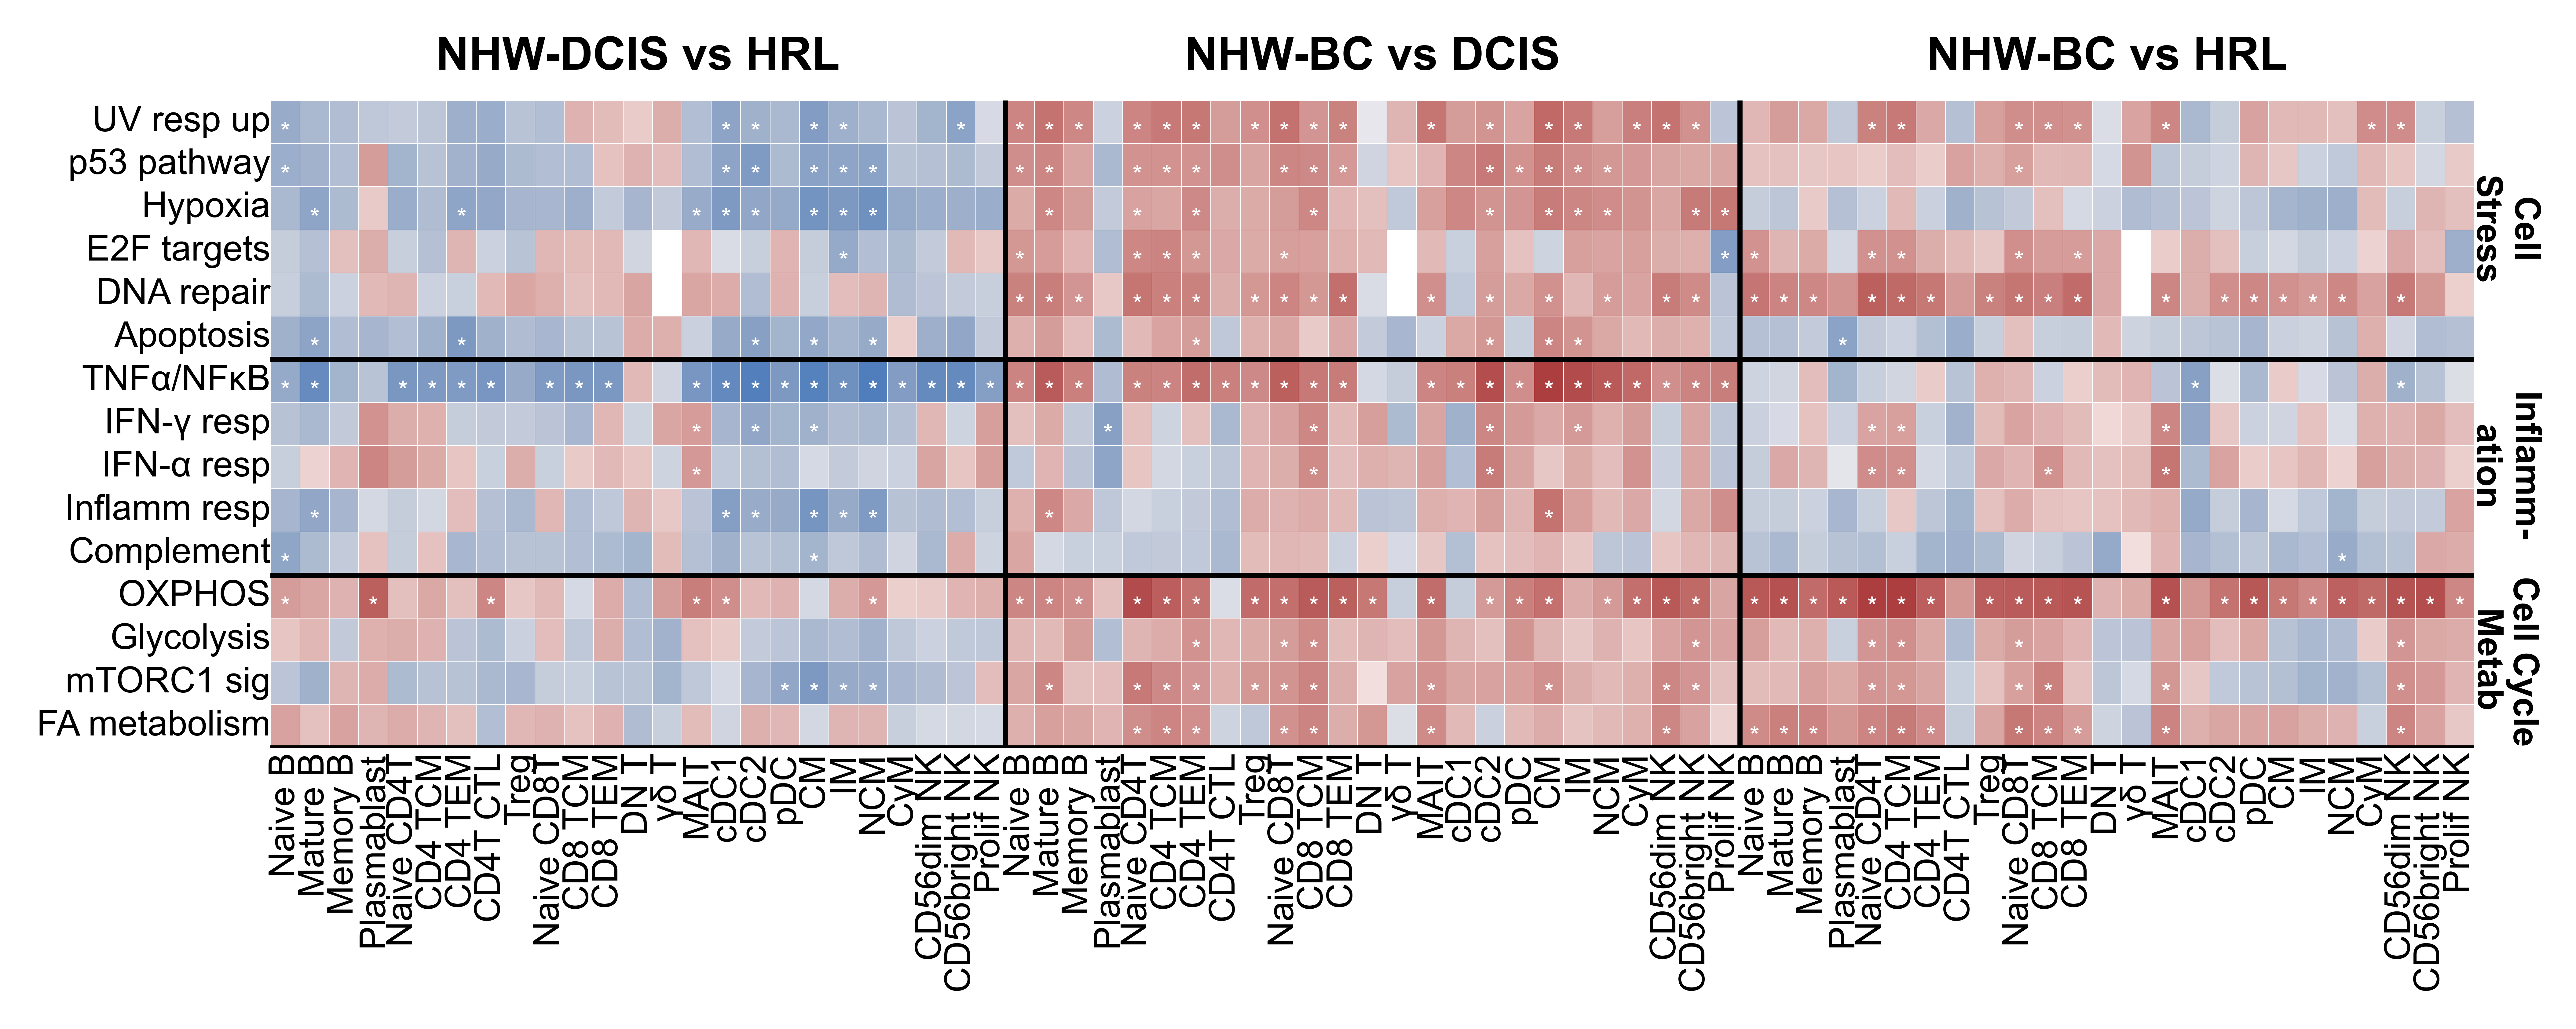

In [23]:
# 2. Create annotation matrix for significance (* if padj < 0.1)

mat_nes_sel = mat_nes.loc[rows_sel, cols_sel]
mat_pdj_sel = mat_pdj.loc[rows_sel, cols_sel]


plt_major_celltype={'B': '#3072C4',
  'T': '#EF763F',
  'DC': '#35A293',
  'Mono': '#B3813E',
  'NK': '#7D4C99'}


colors = sns.color_palette("Paired")
hex_colors = colors.as_hex()

group_palette = {
    # NHW comparisons - cold colors
    'NHW-DCIS vs HRL': hex_colors[0],  # light sky blue
    'NHW-BC vs HRL':   hex_colors[2],  # deep navy blue
    'NHW-BC vs DCIS':  hex_colors[4],  # vivid cyan-teal

    # NHB comparisons - warm colors
    # 'NHB-DCIS vs HRL': hex_colors[1],  # salmon pink
    # 'NHB-BC vs HRL':   hex_colors[3],  # deep crimson red
    # 'NHB-BC vs DCIS':  hex_colors[5]   # vivid orange
}


annot = mat_pdj_sel.applymap(lambda v: '*' if v < 0.05 else '')

# 3. Build celltype color map for x-axis labels
celltype_colors = []
celltype_labels = []
for label in mat_nes_sel.columns:
    # Extract celltype from xlabel (after '___')
    celltype = label.split('___')[1]
    celltype_labels.append(celltype)
    # Identify major group
    group_color = None
    for group, types in cells_group.items():
        if celltype in types:
            group_color = plt_major_celltype[group]
            break
    celltype_colors.append(group_color if group_color else 'black')

# 4. Plot heatmap
fig, ax = plt.subplots(figsize=(7,2.8))
ax.tick_params(axis='y', length=0)
ax.tick_params(axis='y', pad=0)
ax.tick_params(axis='x', length=0)
ax.tick_params(axis='x', pad=1)

hm = sns.heatmap(
    mat_nes_sel,
    ax=ax,
    cmap='vlag',
    center=0,
    vmin = -3,
    vmax = 3,
    annot=annot,
    linecolor='white',
    linewidth=.01,
    fmt='',
    cbar_kws={"shrink": 0.2, "pad": 0.04, "orientation": "horizontal"},
    annot_kws={"va": "top", "ha": "center", "fontsize": 5, "color": "white"}
)

hm.collections[0].colorbar.remove() # remove cbar

# 5. Format y-axis: show all pathways
ax.set_yticks(np.arange(len(mat_nes_sel)) + 0.5)
ax.set_yticklabels([pathway_short_dict[x] for x in mat_nes_sel.index], rotation=0, fontsize=7)

# 6. Format x-axis: show celltype names, rotate, bold, colored
celltype_labels_short = [
    celltype_short.get(x, x) for x in celltype_labels
]

ax.set_xticks(np.arange(len(mat_nes_sel.columns)) + 0.5)
ax.set_xticklabels(
    celltype_labels_short,
    rotation=90,
    fontweight="regular",
    fontsize=7
)

# celltype_labels = [col.split('___')[1] for col in mat_nes_sel.columns]

# ax.set_xticks(np.arange(len(mat_nes_sel.columns)) + 0.5)
# ax.set_xticklabels(celltype_labels, rotation=90, fontweight='regular', fontsize=7)

# for xtick, color in zip(ax.get_xticklabels(), celltype_colors):
#     xtick.set_color(color)

# 7. Add thick horizontal separation lines by pathway groups
pathway_groups = {
    'Cell Stress': ['UV RESPONSE UP','P53 PATHWAY','HYPOXIA','E2F TARGETS','DNA REPAIR','APOPTOSIS'],
    'Inflammation': ['TNFA SIGNALING VIA NFKB','INTERFERON GAMMA RESPONSE','INTERFERON ALPHA RESPONSE','INFLAMMATORY RESPONSE','COMPLEMENT'],
    'Cell Cycle\nMetabolism': ['OXIDATIVE PHOSPHORYLATION','GLYCOLYSIS','MTORC1 SIGNALING','FATTY ACID METABOLISM']#,
    # 'Cancer': Cancer#,
    # 'Miscellaneous': Miscellaneous
}
y_pos = 0
for group, pathways in pathway_groups.items():
    y_pos += len(pathways)
    if y_pos < len(mat_nes):
        ax.axhline(y=y_pos, color='black', linewidth=1)

# 8. Add thick vertical separation lines by subgroup
x_pos = 0
current_subgroup = mat_nes_sel.columns[0].split('___')[0]
for i, col in enumerate(mat_nes_sel.columns):
    subgroup = col.split('___')[0]
    if subgroup != current_subgroup:
        ax.axvline(x=i, color='black', linewidth=1)  # vertical line before new subgroup
        current_subgroup = subgroup
        
plt.xlabel('')
plt.ylabel('')

# 10. Add subgroup titles on top of each subgroup block
subgroup_positions = []
current_subgroup = mat_nes_sel.columns[0].split('___')[0]
start_idx = 0

for i, col in enumerate(mat_nes_sel.columns):
    subgroup = col.split('___')[0]
    if subgroup != current_subgroup:
        mid_pos = (start_idx + i) / 2.0
        subgroup_positions.append((current_subgroup, mid_pos))
        current_subgroup = subgroup
        start_idx = i

## Append the last subgroup
mid_pos = (start_idx + len(mat_nes_sel.columns)) / 2.0
subgroup_positions.append((current_subgroup, mid_pos))


for subgroup, mid_pos in subgroup_positions:
    color = 'black'#group_palette.get(subgroup, 'black')
    ax.text(
        mid_pos,        # center position
        -0.5,           # just above x-axis
        subgroup,
        color=color,
        ha='center',
        va='bottom',
        fontweight='bold',
        fontsize=9,
        transform=ax.transData
    )
    

# 11. Add pathway group labels on the right side of y-axis
y_pos = 0
for group_name, pathways in pathway_groups.items():
    block_size = len(pathways)
    mid_y = y_pos + block_size / 2.0  # center of the block

    group_name_formatted = {
        'Cell Stress':'Cell\nStress',
        'Inflammation':'Inflamm-\nation',
        'Cell Cycle\nMetabolism': 'Cell Cycle\nMetab'
    }
    
    ax.text(
        len(mat_nes_sel.columns) + 1,  # place outside heatmap (right side)
        mid_y,
        group_name_formatted.get(group_name, group_name),
        color='black',
        ha='center',
        va='center',
        fontweight='bold',
        fontsize=7,
        rotation=270,
        clip_on=False,
        transform=ax.transData
    )

    y_pos += block_size
    
plt.tight_layout()
plt.savefig('plots/F3/RRE_Selheatmap_bystageNHW_hallmark.svg')

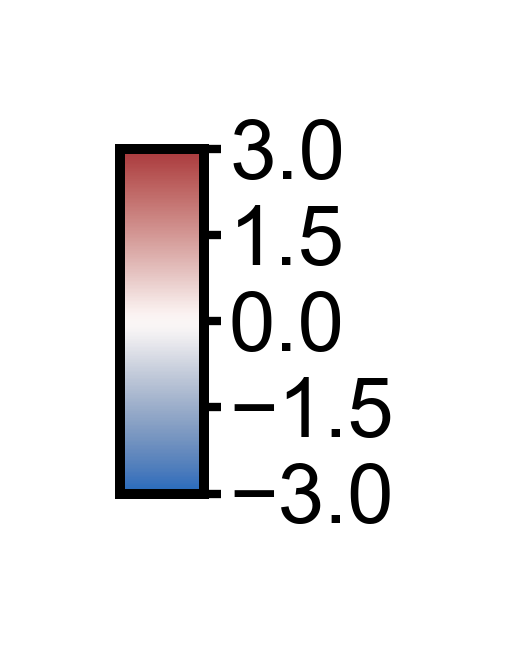

In [24]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# Define cmap and normalization to match your heatmap
cmap = plt.get_cmap("vlag")
norm = TwoSlopeNorm(vmin=-3, vcenter=0, vmax=3)

# Create a compact horizontal colorbar (width=1, height=0.5 inches)
fig_cbar, ax_cbar = plt.subplots(figsize=(.1, 0.7))
fig_cbar.subplots_adjust(bottom=0.5, left=0.25, right=0.95)

cbar = mpl.colorbar.ColorbarBase(
    ax_cbar,
    cmap=cmap,
    norm=norm,
    orientation='vertical',
    ticks=[-3, -1.5, 0, 1.5, 3]
)

# Style
cbar.ax.tick_params(labelsize=5, length=1, pad=.5)
cbar.outline.set_linewidth(0.6)

# Save
fig_cbar.savefig(
    'plots/F3/colorbar_rectangle_small.svg',
    bbox_inches='tight', dpi=600
)
plt.show()

## Main fig - NHB

In [25]:
# 'NHW-DCIS vs HRL',
# 'NHW-BC vs DCIS',
# 'NHW-BC vs HRL',


cols_sel = [
    x for x in mat_nes.columns
    if x.startswith('NHB-DCIS vs HRL')
    or x.startswith('NHB-BC vs DCIS')
    or x.startswith('NHB-BC vs HRL')
]

cols_sel

['NHB-DCIS vs HRL___Naive B',
 'NHB-DCIS vs HRL___Mature B',
 'NHB-DCIS vs HRL___Memory B',
 'NHB-DCIS vs HRL___Plasmablast',
 'NHB-DCIS vs HRL___Naive CD4T',
 'NHB-DCIS vs HRL___Central Memory CD4T',
 'NHB-DCIS vs HRL___Effector Memory CD4T',
 'NHB-DCIS vs HRL___Cytotoxic CD4T',
 'NHB-DCIS vs HRL___Treg',
 'NHB-DCIS vs HRL___Naive CD8T',
 'NHB-DCIS vs HRL___Central Memory CD8T',
 'NHB-DCIS vs HRL___Effector Memory CD8T',
 'NHB-DCIS vs HRL___Double Negative T',
 'NHB-DCIS vs HRL___γδ T',
 'NHB-DCIS vs HRL___MAIT',
 'NHB-DCIS vs HRL___cDC1',
 'NHB-DCIS vs HRL___cDC2',
 'NHB-DCIS vs HRL___pDC',
 'NHB-DCIS vs HRL___Classical Monocyte',
 'NHB-DCIS vs HRL___Intermediate Monocyte',
 'NHB-DCIS vs HRL___Nonclassical Monocyte',
 'NHB-DCIS vs HRL___Cytotoxic Monocyte',
 'NHB-DCIS vs HRL___CD56-dim NK',
 'NHB-DCIS vs HRL___CD56-bright NK',
 'NHB-DCIS vs HRL___Proliferating NK',
 'NHB-BC vs DCIS___Naive B',
 'NHB-BC vs DCIS___Mature B',
 'NHB-BC vs DCIS___Memory B',
 'NHB-BC vs DCIS___Plasmablast'

/tmp/ipykernel_3149594/2476531464.py:30: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot = mat_pdj_sel.applymap(lambda v: '*' if v < 0.05 else '') # padj < 0.05


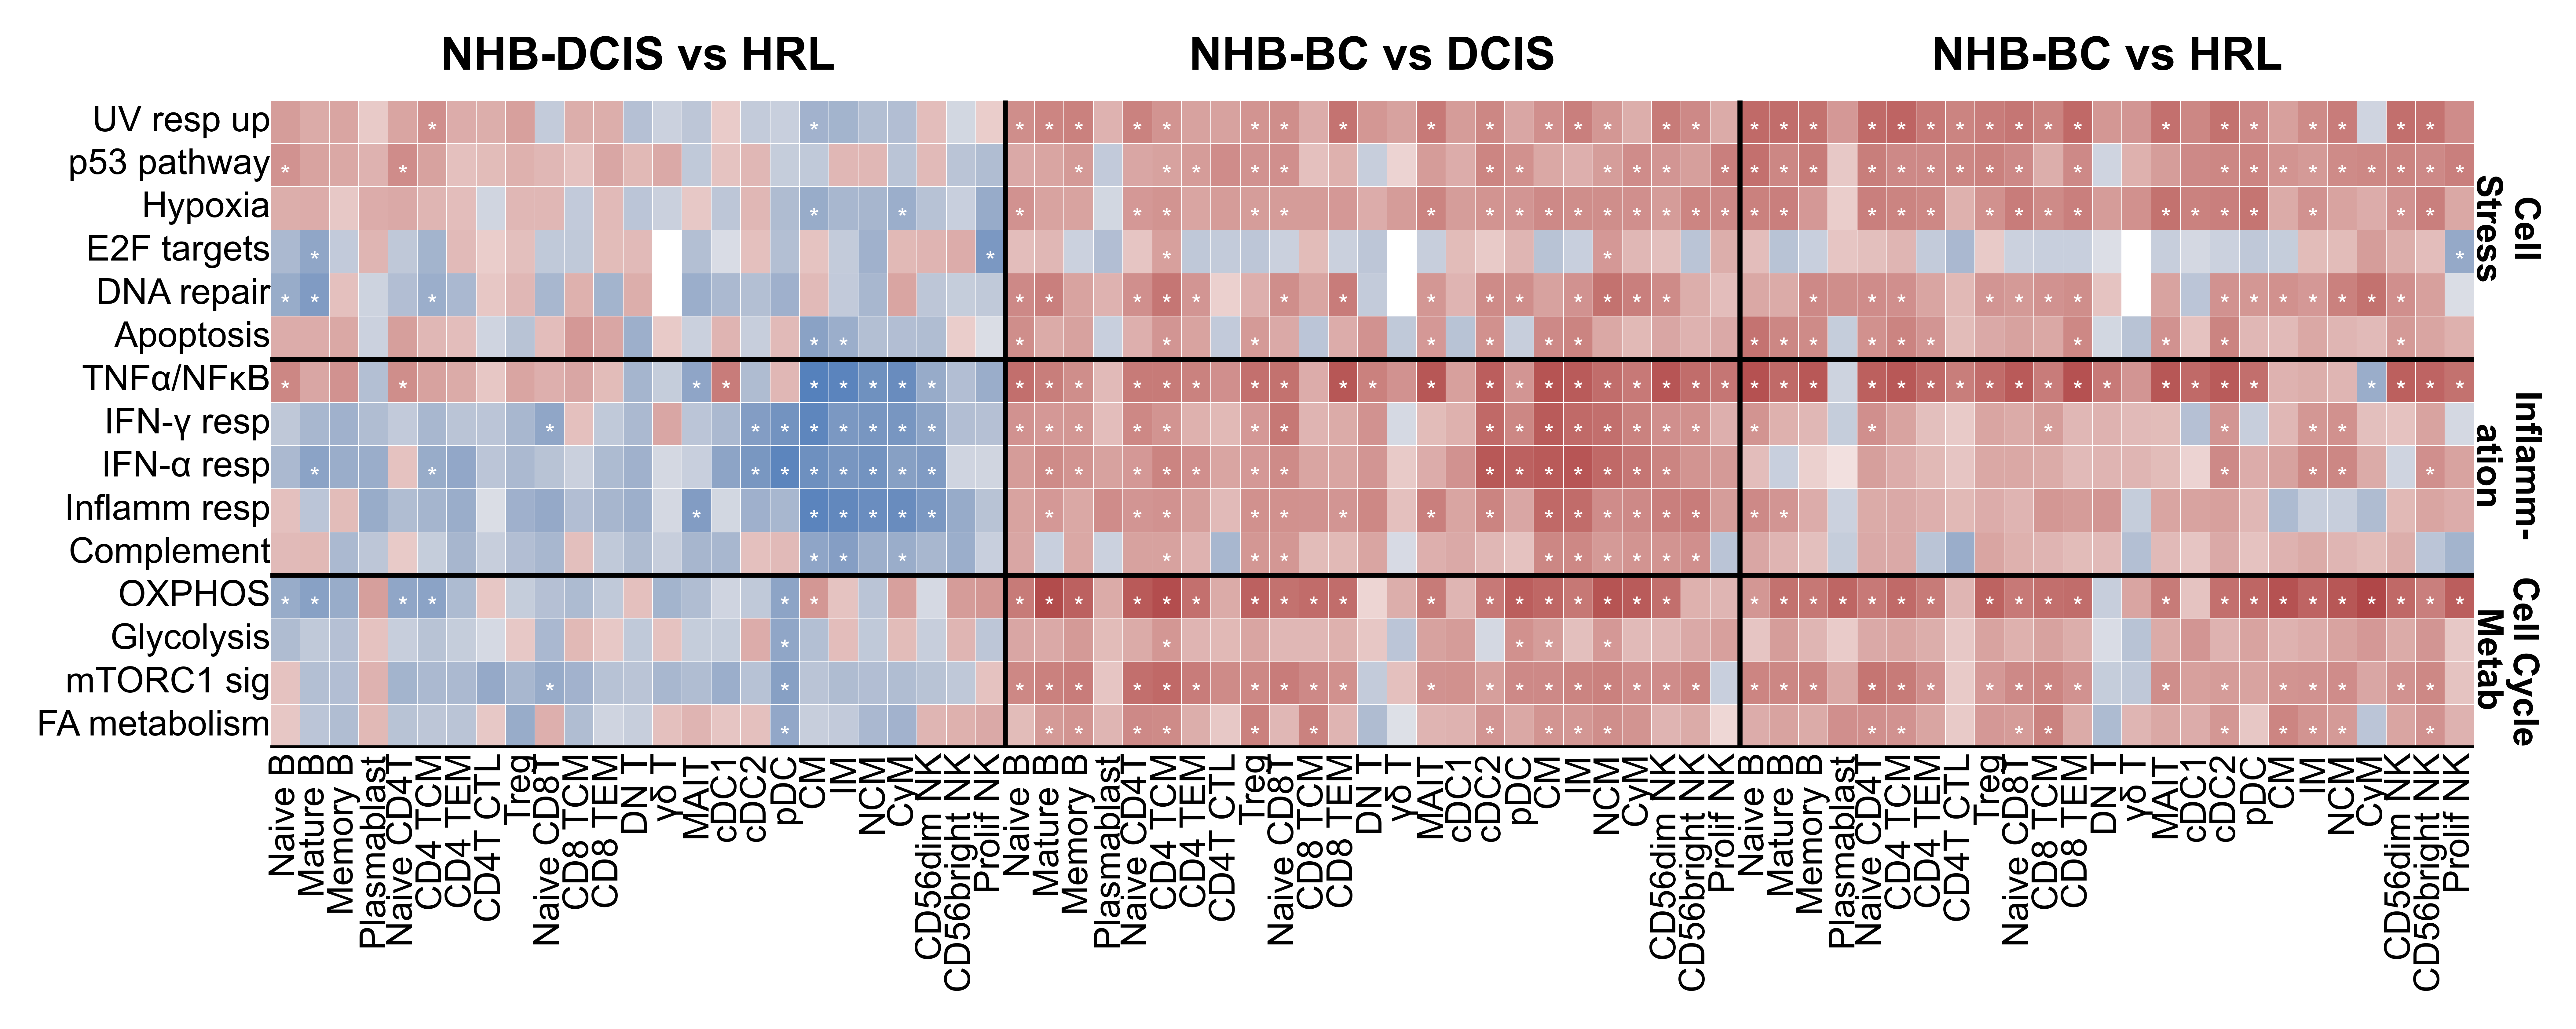

In [26]:
# 2. Create annotation matrix for significance (* if padj < 0.1)

mat_nes_sel = mat_nes.loc[rows_sel, cols_sel]
mat_pdj_sel = mat_pdj.loc[rows_sel, cols_sel]


plt_major_celltype={'B': '#3072C4',
  'T': '#EF763F',
  'DC': '#35A293',
  'Mono': '#B3813E',
  'NK': '#7D4C99'}


colors = sns.color_palette("Paired")
hex_colors = colors.as_hex()

group_palette = {
    # NHW comparisons - cold colors
    # 'NHW-DCIS vs HRL': hex_colors[0],  # light sky blue
    # 'NHW-BC vs HRL':   hex_colors[2],  # deep navy blue
    # 'NHW-BC vs DCIS':  hex_colors[4],  # vivid cyan-teal

    # NHB comparisons - warm colors
    'NHB-DCIS vs HRL': hex_colors[1],  # salmon pink
    'NHB-BC vs HRL':   hex_colors[3],  # deep crimson red
    'NHB-BC vs DCIS':  hex_colors[5]   # vivid orange
}


annot = mat_pdj_sel.applymap(lambda v: '*' if v < 0.05 else '') # padj < 0.05

# 3. Build celltype color map for x-axis labels
celltype_colors = []
celltype_labels = []
for label in mat_nes_sel.columns:
    # Extract celltype from xlabel (after '___')
    celltype = label.split('___')[1]
    celltype_labels.append(celltype)
    # Identify major group
    group_color = None
    for group, types in cells_group.items():
        if celltype in types:
            group_color = plt_major_celltype[group]
            break
    celltype_colors.append(group_color if group_color else 'black')

# 4. Plot heatmap
fig, ax = plt.subplots(figsize=(7,2.8))
ax.tick_params(axis='y', length=0)
ax.tick_params(axis='y', pad=0)
ax.tick_params(axis='x', length=0)
ax.tick_params(axis='x', pad=1)

hm = sns.heatmap(
    mat_nes_sel,
    ax=ax,
    cmap='vlag',
    center=0,
    vmin = -3,
    vmax = 3,
    annot=annot,
    linecolor='white',
    linewidth=.01,
    fmt='',
    cbar_kws={"shrink": 0.2, "pad": 0.04, "orientation": "horizontal"},
    annot_kws={"va": "top", "ha": "center", "fontsize": 5, "color": "white"}
)

hm.collections[0].colorbar.remove() # remove cbar

# 5. Format y-axis: show all pathways
ax.set_yticks(np.arange(len(mat_nes_sel)) + 0.5)
ax.set_yticklabels([pathway_short_dict[x] for x in mat_nes_sel.index], rotation=0, fontsize=7)

# 6. Format x-axis: show celltype names, rotate, bold, colored
celltype_labels_short = [
    celltype_short.get(x, x) for x in celltype_labels
]

ax.set_xticks(np.arange(len(mat_nes_sel.columns)) + 0.5)
ax.set_xticklabels(
    celltype_labels_short,
    rotation=90,
    fontweight="regular",
    fontsize=7
)

# celltype_labels = [col.split('___')[1] for col in mat_nes_sel.columns]

# ax.set_xticks(np.arange(len(mat_nes_sel.columns)) + 0.5)
# ax.set_xticklabels(celltype_labels, rotation=90, fontweight='regular', fontsize=7)

# for xtick, color in zip(ax.get_xticklabels(), celltype_colors):
#     xtick.set_color(color)

# 7. Add thick horizontal separation lines by pathway groups
pathway_groups = {
    'Cell Stress': ['UV RESPONSE UP','P53 PATHWAY','HYPOXIA','E2F TARGETS','DNA REPAIR','APOPTOSIS'],
    'Inflammation': ['TNFA SIGNALING VIA NFKB','INTERFERON GAMMA RESPONSE','INTERFERON ALPHA RESPONSE','INFLAMMATORY RESPONSE','COMPLEMENT'],
    'Cell Cycle\nMetabolism': ['OXIDATIVE PHOSPHORYLATION','GLYCOLYSIS','MTORC1 SIGNALING','FATTY ACID METABOLISM']#,
    # 'Cancer': Cancer#,
    # 'Miscellaneous': Miscellaneous
}
y_pos = 0
for group, pathways in pathway_groups.items():
    y_pos += len(pathways)
    if y_pos < len(mat_nes):
        ax.axhline(y=y_pos, color='black', linewidth=1)

# 8. Add thick vertical separation lines by subgroup
x_pos = 0
current_subgroup = mat_nes_sel.columns[0].split('___')[0]
for i, col in enumerate(mat_nes_sel.columns):
    subgroup = col.split('___')[0]
    if subgroup != current_subgroup:
        ax.axvline(x=i, color='black', linewidth=1)  # vertical line before new subgroup
        current_subgroup = subgroup
        
plt.xlabel('')
plt.ylabel('')

# 10. Add subgroup titles on top of each subgroup block
subgroup_positions = []
current_subgroup = mat_nes_sel.columns[0].split('___')[0]
start_idx = 0

for i, col in enumerate(mat_nes_sel.columns):
    subgroup = col.split('___')[0]
    if subgroup != current_subgroup:
        mid_pos = (start_idx + i) / 2.0
        subgroup_positions.append((current_subgroup, mid_pos))
        current_subgroup = subgroup
        start_idx = i

## Append the last subgroup
mid_pos = (start_idx + len(mat_nes_sel.columns)) / 2.0
subgroup_positions.append((current_subgroup, mid_pos))


for subgroup, mid_pos in subgroup_positions:
    color = 'black'#group_palette.get(subgroup, 'black')
    ax.text(
        mid_pos,        # center position
        -0.5,           # just above x-axis
        subgroup,
        color=color,
        ha='center',
        va='bottom',
        fontweight='bold',
        fontsize=9,
        transform=ax.transData
    )
    

# 11. Add pathway group labels on the right side of y-axis
y_pos = 0
for group_name, pathways in pathway_groups.items():
    block_size = len(pathways)
    mid_y = y_pos + block_size / 2.0  # center of the block

    group_name_formatted = {
        'Cell Stress':'Cell\nStress',
        'Inflammation':'Inflamm-\nation',
        'Cell Cycle\nMetabolism': 'Cell Cycle\nMetab'
    }
    
    ax.text(
        len(mat_nes_sel.columns) + 1,  # place outside heatmap (right side)
        mid_y,
        group_name_formatted.get(group_name, group_name),
        color='black',
        ha='center',
        va='center',
        fontweight='bold',
        fontsize=7,
        rotation=270,
        clip_on=False,
        transform=ax.transData
    )

    y_pos += block_size
    
plt.tight_layout()
plt.savefig('plots/F3/RRE_Selheatmap_bystageNHB_hallmark.svg')

## Supp - NHW

In [27]:
# 'NHW-DCIS vs HRL',
# 'NHW-BC vs DCIS',
# 'NHW-BC vs HRL',


cols_sel = [
    x for x in mat_nes.columns
    if x.startswith('NHW-DCIS vs HRL')
    or x.startswith('NHW-BC vs DCIS')
    or x.startswith('NHW-BC vs HRL')
]

cols_sel

['NHW-DCIS vs HRL___Naive B',
 'NHW-DCIS vs HRL___Mature B',
 'NHW-DCIS vs HRL___Memory B',
 'NHW-DCIS vs HRL___Plasmablast',
 'NHW-DCIS vs HRL___Naive CD4T',
 'NHW-DCIS vs HRL___Central Memory CD4T',
 'NHW-DCIS vs HRL___Effector Memory CD4T',
 'NHW-DCIS vs HRL___Cytotoxic CD4T',
 'NHW-DCIS vs HRL___Treg',
 'NHW-DCIS vs HRL___Naive CD8T',
 'NHW-DCIS vs HRL___Central Memory CD8T',
 'NHW-DCIS vs HRL___Effector Memory CD8T',
 'NHW-DCIS vs HRL___Double Negative T',
 'NHW-DCIS vs HRL___γδ T',
 'NHW-DCIS vs HRL___MAIT',
 'NHW-DCIS vs HRL___cDC1',
 'NHW-DCIS vs HRL___cDC2',
 'NHW-DCIS vs HRL___pDC',
 'NHW-DCIS vs HRL___Classical Monocyte',
 'NHW-DCIS vs HRL___Intermediate Monocyte',
 'NHW-DCIS vs HRL___Nonclassical Monocyte',
 'NHW-DCIS vs HRL___Cytotoxic Monocyte',
 'NHW-DCIS vs HRL___CD56-dim NK',
 'NHW-DCIS vs HRL___CD56-bright NK',
 'NHW-DCIS vs HRL___Proliferating NK',
 'NHW-BC vs DCIS___Naive B',
 'NHW-BC vs DCIS___Mature B',
 'NHW-BC vs DCIS___Memory B',
 'NHW-BC vs DCIS___Plasmablast'

In [28]:
Cell_stress + Inflammation + Cell_cycle_metabolism

['UV RESPONSE UP',
 'UV RESPONSE DN',
 'UNFOLDED PROTEIN RESPONSE',
 'REACTIVE OXYGEN SPECIES PATHWAY',
 'P53 PATHWAY',
 'HYPOXIA',
 'G2M CHECKPOINT',
 'E2F TARGETS',
 'DNA REPAIR',
 'APOPTOSIS',
 'TNFA SIGNALING VIA NFKB',
 'INTERFERON GAMMA RESPONSE',
 'INTERFERON ALPHA RESPONSE',
 'IL6 JAK STAT3 SIGNALING',
 'IL2 STAT5 SIGNALING',
 'INFLAMMATORY RESPONSE',
 'COMPLEMENT',
 'ALLOGRAFT REJECTION',
 'PROTEIN SECRETION',
 'PEROXISOME',
 'OXIDATIVE PHOSPHORYLATION',
 'MTORC1 SIGNALING',
 'GLYCOLYSIS',
 'FATTY ACID METABOLISM',
 'ADIPOGENESIS']

In [29]:
rows_exclude = [
    'UV RESPONSE UP','P53 PATHWAY','HYPOXIA','E2F TARGETS','DNA REPAIR','APOPTOSIS', # cell stress
    'TNFA SIGNALING VIA NFKB','INTERFERON GAMMA RESPONSE','INTERFERON ALPHA RESPONSE','INFLAMMATORY RESPONSE','COMPLEMENT', # inflammation
    'OXIDATIVE PHOSPHORYLATION','GLYCOLYSIS','MTORC1 SIGNALING','FATTY ACID METABOLISM' # cell cycle & metabolism
    
]

other_Cell_stress = [x for x in Cell_stress if x not in rows_exclude]
other_Inflammation = [x for x in Inflammation if x not in rows_exclude]
other_Cell_cycle_metabolism = [x for x in Cell_cycle_metabolism if x not in rows_exclude]
other_Cancer = [x for x in Cancer if x not in rows_exclude]
other_Miscellaneous = [x for x in Miscellaneous if x not in rows_exclude]

rows_sel = other_Cell_stress + other_Inflammation + other_Cell_cycle_metabolism + other_Cancer + other_Miscellaneous

In [31]:
pathway_short_dict.update({
    "UV RESPONSE DN": "UV resp dn",
    "UNFOLDED PROTEIN RESPONSE": "UPR",
    "REACTIVE OXYGEN SPECIES PATHWAY": "ROS path",
    "G2M CHECKPOINT": "G2M checkpt",
    "IL6 JAK STAT3 SIGNALING": "IL6/JAK/STAT3",
    "IL2 STAT5 SIGNALING": "IL2/STAT5",
    "ALLOGRAFT REJECTION": "Allograft rej",
    "PROTEIN SECRETION": "Protein secretion",
    "PEROXISOME": "Peroxisome",
    "ADIPOGENESIS": "Adipogenesis",
    "TGF BETA SIGNALING": "TGFβ sig",
    "PI3K AKT MTOR SIGNALING": "PI3K/AKT/mTOR",
    "MYC TARGETS V2": "MYC targets V2",
    "MYC TARGETS V1": "MYC targets V1",
    "MITOTIC SPINDLE": "Mitotic spindle",
    "KRAS SIGNALING UP": "KRAS sig up",
    "KRAS SIGNALING DN": "KRAS sig dn",
    "ESTROGEN RESPONSE EARLY": "Estrogen resp early",
    "ESTROGEN RESPONSE LATE": "Estrogen resp late",
    "EPITHELIAL MESENCHYMAL TRANSITION": "EMT",
    "APICAL SURFACE": "Apical surf",
    "APICAL JUNCTION": "Apical junc",
    "ANDROGEN RESPONSE": "Androgen resp",
    "XENOBIOTIC METABOLISM": "Xenobiotic metab",
    "WNT BETA CATENIN SIGNALING": "Wnt/β-catenin",
    "SPERMATOGENESIS": "Spermatogenesis",
    "PANCREAS BETA CELLS": "Pancreas β cells",
    "NOTCH SIGNALING": "Notch sig",
    "MYOGENESIS": "Myogenesis",
    "HEME METABOLISM": "Heme metab",
    "HEDGEHOG SIGNALING": "Hedgehog sig",
    "COAGULATION": "Coagulation",
    "CHOLESTEROL HOMEOSTASIS": "Cholesterol homeo",
    "BILE ACID METABOLISM": "Bile acid metab",
    "ANGIOGENESIS": "Angiogenesis",
})

/tmp/ipykernel_3149594/751171310.py:30: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot = mat_pdj_sel.applymap(lambda v: '*' if v < 0.05 else '')


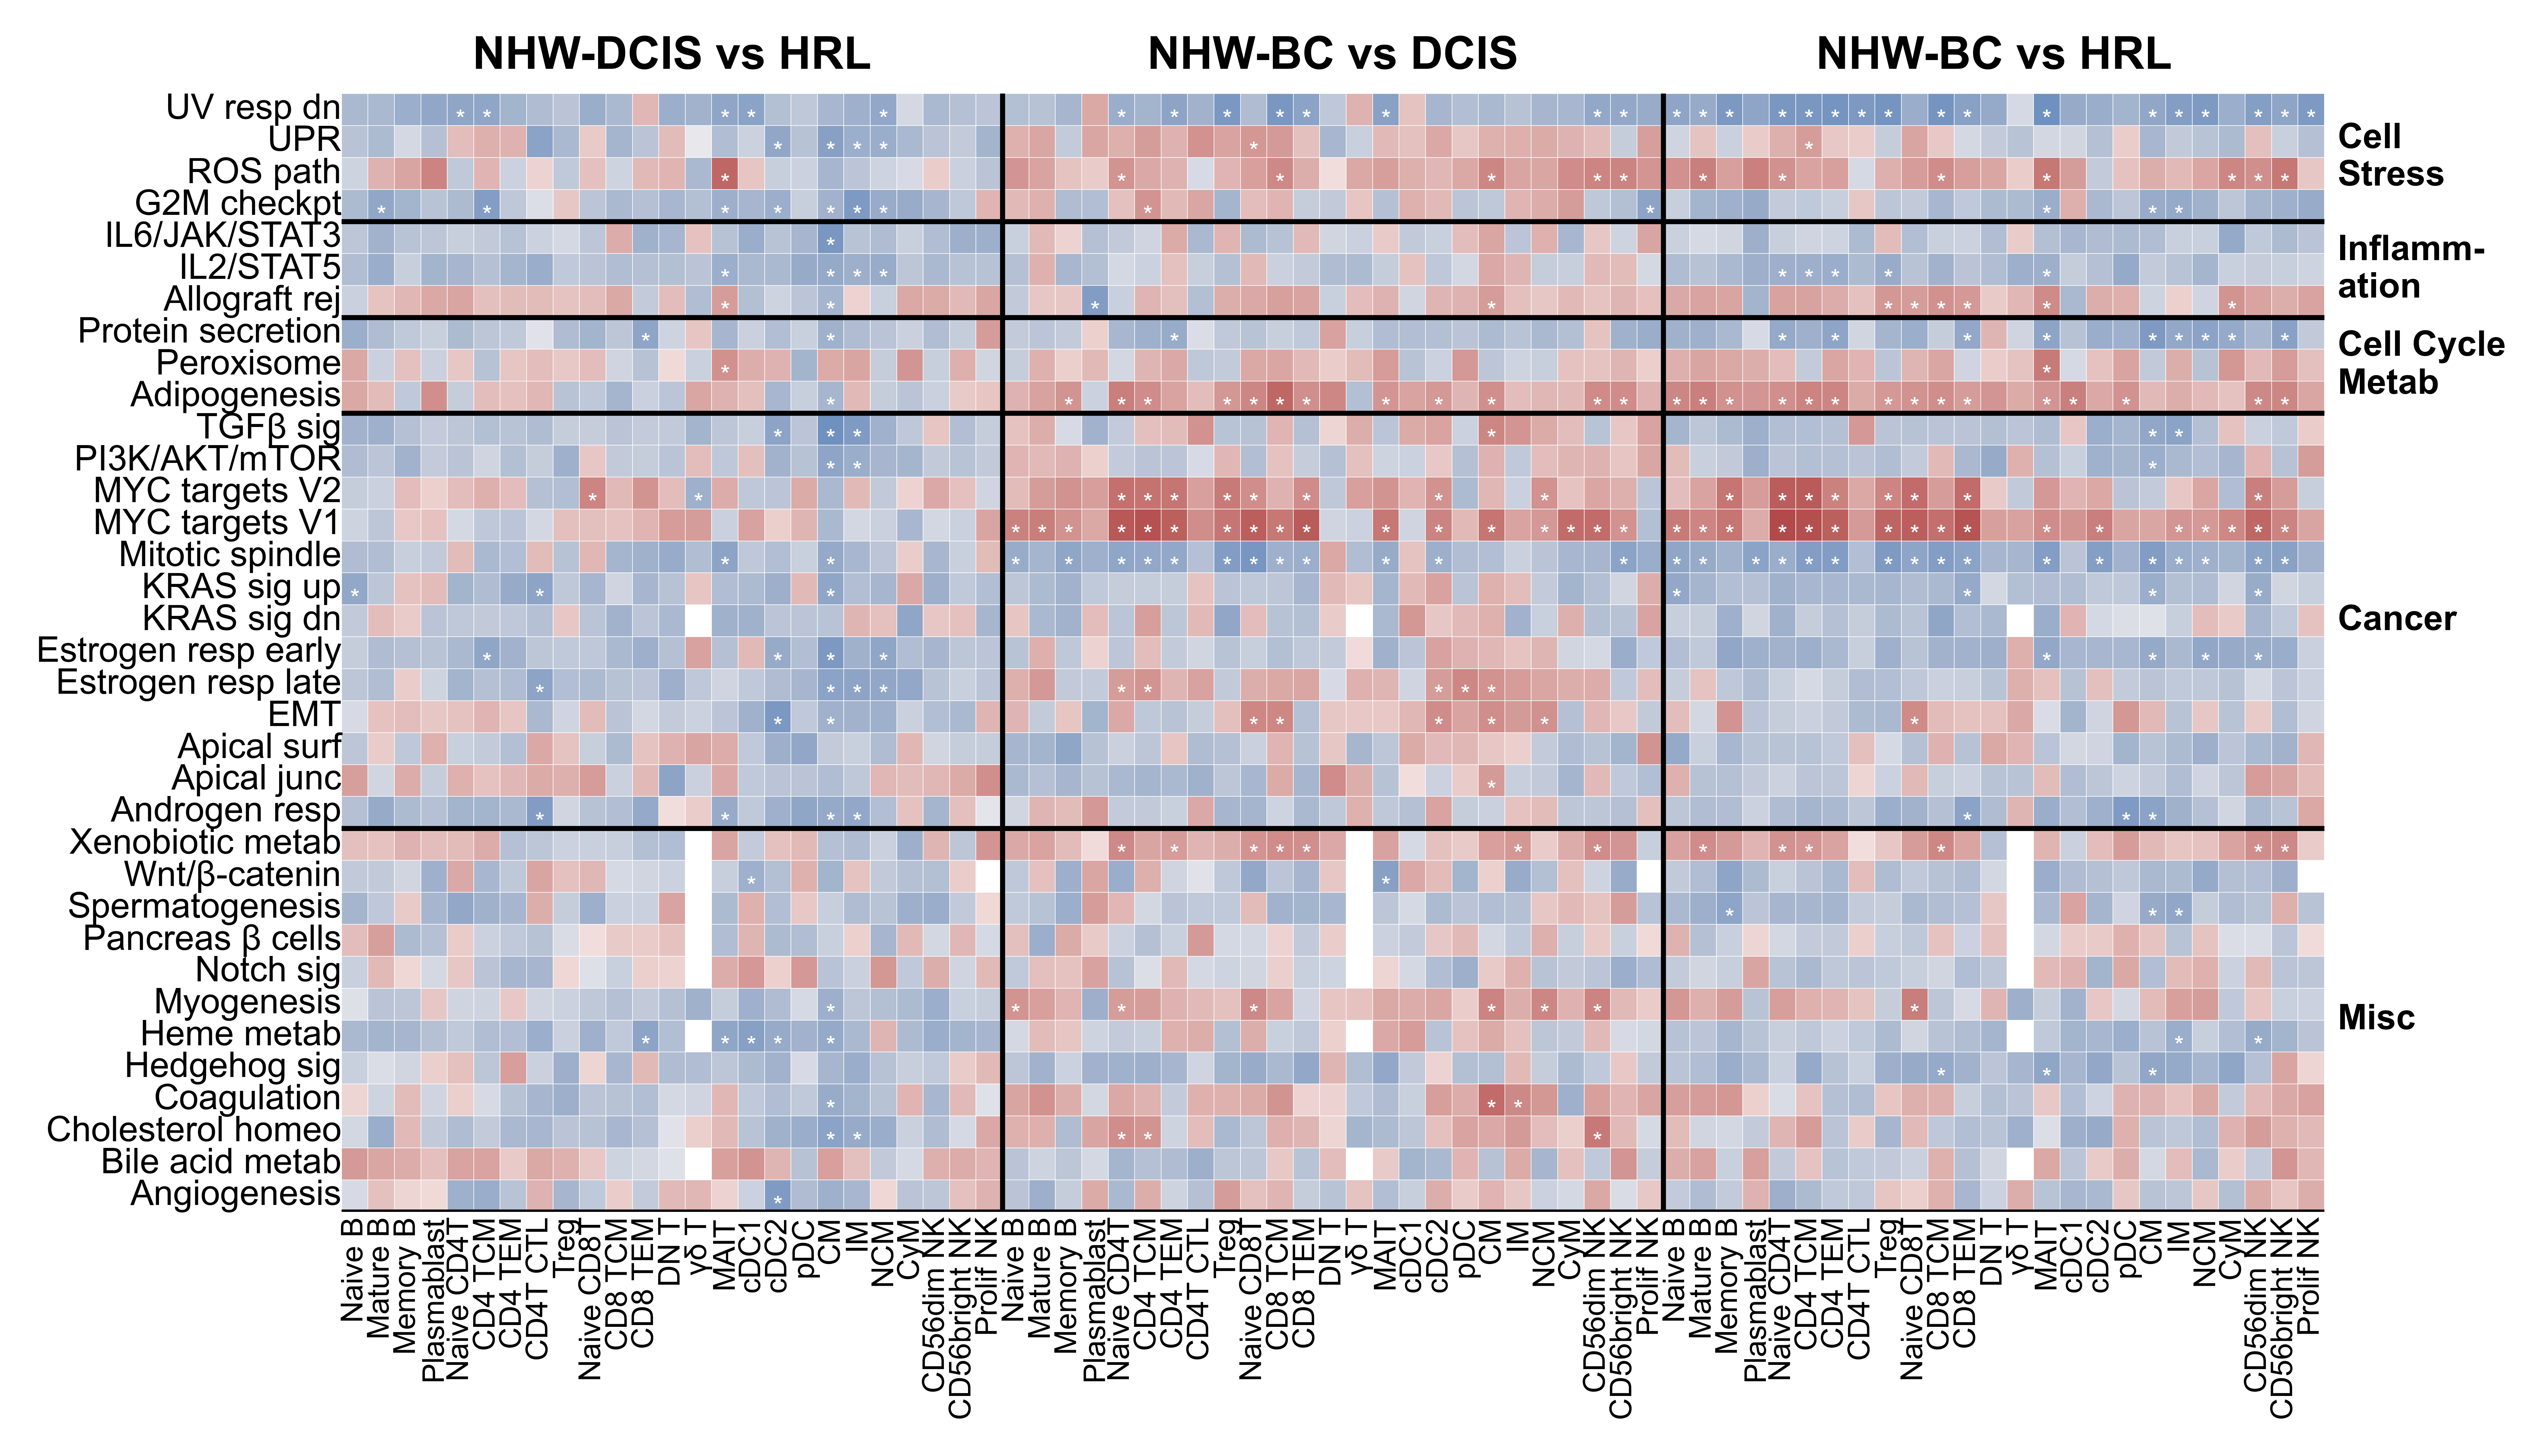

In [33]:
# 2. Create annotation matrix for significance (* if padj < 0.1)

mat_nes_sel = mat_nes.loc[rows_sel, cols_sel]
mat_pdj_sel = mat_pdj.loc[rows_sel, cols_sel]


plt_major_celltype={'B': '#3072C4',
  'T': '#EF763F',
  'DC': '#35A293',
  'Mono': '#B3813E',
  'NK': '#7D4C99'}


colors = sns.color_palette("Paired")
hex_colors = colors.as_hex()

group_palette = {
    # NHW comparisons - cold colors
    'NHW-DCIS vs HRL': hex_colors[0],  # light sky blue
    'NHW-BC vs HRL':   hex_colors[2],  # deep navy blue
    'NHW-BC vs DCIS':  hex_colors[4],  # vivid cyan-teal

    # NHB comparisons - warm colors
    # 'NHB-DCIS vs HRL': hex_colors[1],  # salmon pink
    # 'NHB-BC vs HRL':   hex_colors[3],  # deep crimson red
    # 'NHB-BC vs DCIS':  hex_colors[5]   # vivid orange
}


annot = mat_pdj_sel.applymap(lambda v: '*' if v < 0.05 else '')

# 3. Build celltype color map for x-axis labels
celltype_colors = []
celltype_labels = []
for label in mat_nes_sel.columns:
    # Extract celltype from xlabel (after '___')
    celltype = label.split('___')[1]
    celltype_labels.append(celltype)
    # Identify major group
    group_color = None
    for group, types in cells_group.items():
        if celltype in types:
            group_color = plt_major_celltype[group]
            break
    celltype_colors.append(group_color if group_color else 'black')

# 4. Plot heatmap
fig, ax = plt.subplots(figsize=(7,4))
ax.tick_params(axis='y', length=0)
ax.tick_params(axis='y', pad=0)
ax.tick_params(axis='x', length=0)
ax.tick_params(axis='x', pad=1)

hm = sns.heatmap(
    mat_nes_sel,
    ax=ax,
    cmap='vlag',
    center=0,
    vmin = -3,
    vmax = 3,
    annot=annot,
    linecolor='white',
    linewidth=.01,
    fmt='',
    cbar_kws={"shrink": 0.2, "pad": 0.04, "orientation": "horizontal"},
    annot_kws={"va": "top", "ha": "center", "fontsize": 5, "color": "white"}
)

hm.collections[0].colorbar.remove() # remove cbar

# 5. Format y-axis: show all pathways
ax.set_yticks(np.arange(len(mat_nes_sel)) + 0.5)
ax.set_yticklabels([pathway_short_dict[x] for x in mat_nes_sel.index], rotation=0, fontsize=7)

# 6. Format x-axis: show celltype names, rotate, bold, colored
celltype_labels_short = [
    celltype_short.get(x, x) for x in celltype_labels
]

ax.set_xticks(np.arange(len(mat_nes_sel.columns)) + 0.5)
ax.set_xticklabels(
    celltype_labels_short,
    rotation=90,
    fontweight="regular",
    fontsize=6
)

# for xtick, color in zip(ax.get_xticklabels(), celltype_colors):
#     xtick.set_color(color)

# 7. Add thick horizontal separation lines by pathway groups
pathway_groups = {
    'Cell Stress': other_Cell_stress,
    'Inflammation': other_Inflammation,
    'Cell Cycle\nMetabolism': other_Cell_cycle_metabolism,
    'Cancer': other_Cancer,
    'Miscellaneous': other_Miscellaneous
}
y_pos = 0
for group, pathways in pathway_groups.items():
    y_pos += len(pathways)
    if y_pos < len(mat_nes):
        ax.axhline(y=y_pos, color='black', linewidth=1)

# 8. Add thick vertical separation lines by subgroup
x_pos = 0
current_subgroup = mat_nes_sel.columns[0].split('___')[0]
for i, col in enumerate(mat_nes_sel.columns):
    subgroup = col.split('___')[0]
    if subgroup != current_subgroup:
        ax.axvline(x=i, color='black', linewidth=1)  # vertical line before new subgroup
        current_subgroup = subgroup
        
plt.xlabel('')
plt.ylabel('')

# 10. Add subgroup titles on top of each subgroup block
subgroup_positions = []
current_subgroup = mat_nes_sel.columns[0].split('___')[0]
start_idx = 0

for i, col in enumerate(mat_nes_sel.columns):
    subgroup = col.split('___')[0]
    if subgroup != current_subgroup:
        mid_pos = (start_idx + i) / 2.0
        subgroup_positions.append((current_subgroup, mid_pos))
        current_subgroup = subgroup
        start_idx = i

## Append the last subgroup
mid_pos = (start_idx + len(mat_nes_sel.columns)) / 2.0
subgroup_positions.append((current_subgroup, mid_pos))


for subgroup, mid_pos in subgroup_positions:
    color = 'black'#group_palette.get(subgroup, 'black')
    ax.text(
        mid_pos,        # center position
        -0.5,           # just above x-axis
        subgroup,
        color=color,
        ha='center',
        va='bottom',
        fontweight='bold',
        fontsize=9,
        transform=ax.transData
    )
    

# 11. Add pathway group labels on the right side of y-axis
y_pos = 0
for group_name, pathways in pathway_groups.items():
    block_size = len(pathways)
    mid_y = y_pos + block_size / 2.0  # center of the block
    
    group_name_formatted = {
        'Cell Stress':'Cell\nStress',
        'Inflammation':'Inflamm-\nation',
        'Cell Cycle\nMetabolism': 'Cell Cycle\nMetab',
        'Cancer':'Cancer',
        'Miscellaneous':'Misc'
    }
    
    ax.text(
        len(mat_nes_sel.columns) + .5,  # place outside heatmap (right side)
        mid_y,
        group_name_formatted.get(group_name, group_name),
        color='black',
        ha='left',
        va='center',
        fontweight='bold',
        fontsize=7,
        rotation=0,
        clip_on=False,
        transform=ax.transData
    )

    y_pos += block_size
    
plt.tight_layout()
plt.savefig('plots/S3/RRE_heatmap_bystageNHW_hallmark.svg')

## Supp - NHB

In [11]:
# 'NHW-DCIS vs HRL',
# 'NHW-BC vs DCIS',
# 'NHW-BC vs HRL',


cols_sel = [
    x for x in mat_nes.columns
    if x.startswith('NHB-DCIS vs HRL')
    or x.startswith('NHB-BC vs DCIS')
    or x.startswith('NHB-BC vs HRL')
]

cols_sel

['NHB-DCIS vs HRL___Naive B',
 'NHB-DCIS vs HRL___Mature B',
 'NHB-DCIS vs HRL___Memory B',
 'NHB-DCIS vs HRL___Plasmablast',
 'NHB-DCIS vs HRL___Naive CD4T',
 'NHB-DCIS vs HRL___Central Memory CD4T',
 'NHB-DCIS vs HRL___Effector Memory CD4T',
 'NHB-DCIS vs HRL___Cytotoxic CD4T',
 'NHB-DCIS vs HRL___Treg',
 'NHB-DCIS vs HRL___Naive CD8T',
 'NHB-DCIS vs HRL___Central Memory CD8T',
 'NHB-DCIS vs HRL___Effector Memory CD8T',
 'NHB-DCIS vs HRL___Double Negative T',
 'NHB-DCIS vs HRL___γδ T',
 'NHB-DCIS vs HRL___MAIT',
 'NHB-DCIS vs HRL___cDC1',
 'NHB-DCIS vs HRL___cDC2',
 'NHB-DCIS vs HRL___pDC',
 'NHB-DCIS vs HRL___Classical Monocyte',
 'NHB-DCIS vs HRL___Intermediate Monocyte',
 'NHB-DCIS vs HRL___Nonclassical Monocyte',
 'NHB-DCIS vs HRL___Cytotoxic Monocyte',
 'NHB-DCIS vs HRL___CD56-dim NK',
 'NHB-DCIS vs HRL___CD56-bright NK',
 'NHB-DCIS vs HRL___Proliferating NK',
 'NHB-BC vs DCIS___Naive B',
 'NHB-BC vs DCIS___Mature B',
 'NHB-BC vs DCIS___Memory B',
 'NHB-BC vs DCIS___Plasmablast'

In [12]:
rows_exclude = [
    'UV RESPONSE UP','P53 PATHWAY','HYPOXIA','E2F TARGETS','DNA REPAIR','APOPTOSIS', # cell stress
    'TNFA SIGNALING VIA NFKB','INTERFERON GAMMA RESPONSE','INTERFERON ALPHA RESPONSE','INFLAMMATORY RESPONSE','COMPLEMENT', # inflammation
    'OXIDATIVE PHOSPHORYLATION','GLYCOLYSIS','MTORC1 SIGNALING','FATTY ACID METABOLISM' # cell cycle & metabolism
    
]

other_Cell_stress = [x for x in Cell_stress if x not in rows_exclude]
other_Inflammation = [x for x in Inflammation if x not in rows_exclude]
other_Cell_cycle_metabolism = [x for x in Cell_cycle_metabolism if x not in rows_exclude]
other_Cancer = [x for x in Cancer if x not in rows_exclude]
other_Miscellaneous = [x for x in Miscellaneous if x not in rows_exclude]

rows_sel = other_Cell_stress + other_Inflammation + other_Cell_cycle_metabolism + other_Cancer + other_Miscellaneous

In [15]:
pathway_short_dict.update({
    "UV RESPONSE DN": "UV resp dn",
    "UNFOLDED PROTEIN RESPONSE": "UPR",
    "REACTIVE OXYGEN SPECIES PATHWAY": "ROS path",
    "G2M CHECKPOINT": "G2M checkpt",
    "IL6 JAK STAT3 SIGNALING": "IL6/JAK/STAT3",
    "IL2 STAT5 SIGNALING": "IL2/STAT5",
    "ALLOGRAFT REJECTION": "Allograft rej",
    "PROTEIN SECRETION": "Protein secretion",
    "PEROXISOME": "Peroxisome",
    "ADIPOGENESIS": "Adipogenesis",
    "TGF BETA SIGNALING": "TGFβ sig",
    "PI3K AKT MTOR SIGNALING": "PI3K/AKT/mTOR",
    "MYC TARGETS V2": "MYC targets V2",
    "MYC TARGETS V1": "MYC targets V1",
    "MITOTIC SPINDLE": "Mitotic spindle",
    "KRAS SIGNALING UP": "KRAS sig up",
    "KRAS SIGNALING DN": "KRAS sig dn",
    "ESTROGEN RESPONSE EARLY": "Estrogen resp early",
    "ESTROGEN RESPONSE LATE": "Estrogen resp late",
    "EPITHELIAL MESENCHYMAL TRANSITION": "EMT",
    "APICAL SURFACE": "Apical surf",
    "APICAL JUNCTION": "Apical junc",
    "ANDROGEN RESPONSE": "Androgen resp",
    "XENOBIOTIC METABOLISM": "Xenobiotic metab",
    "WNT BETA CATENIN SIGNALING": "Wnt/β-catenin",
    "SPERMATOGENESIS": "Spermatogenesis",
    "PANCREAS BETA CELLS": "Pancreas β cells",
    "NOTCH SIGNALING": "Notch sig",
    "MYOGENESIS": "Myogenesis",
    "HEME METABOLISM": "Heme metab",
    "HEDGEHOG SIGNALING": "Hedgehog sig",
    "COAGULATION": "Coagulation",
    "CHOLESTEROL HOMEOSTASIS": "Cholesterol homeo",
    "BILE ACID METABOLISM": "Bile acid metab",
    "ANGIOGENESIS": "Angiogenesis",
})

/tmp/ipykernel_804185/1368484624.py:30: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot = mat_pdj_sel.applymap(lambda v: '*' if v < 0.05 else '')


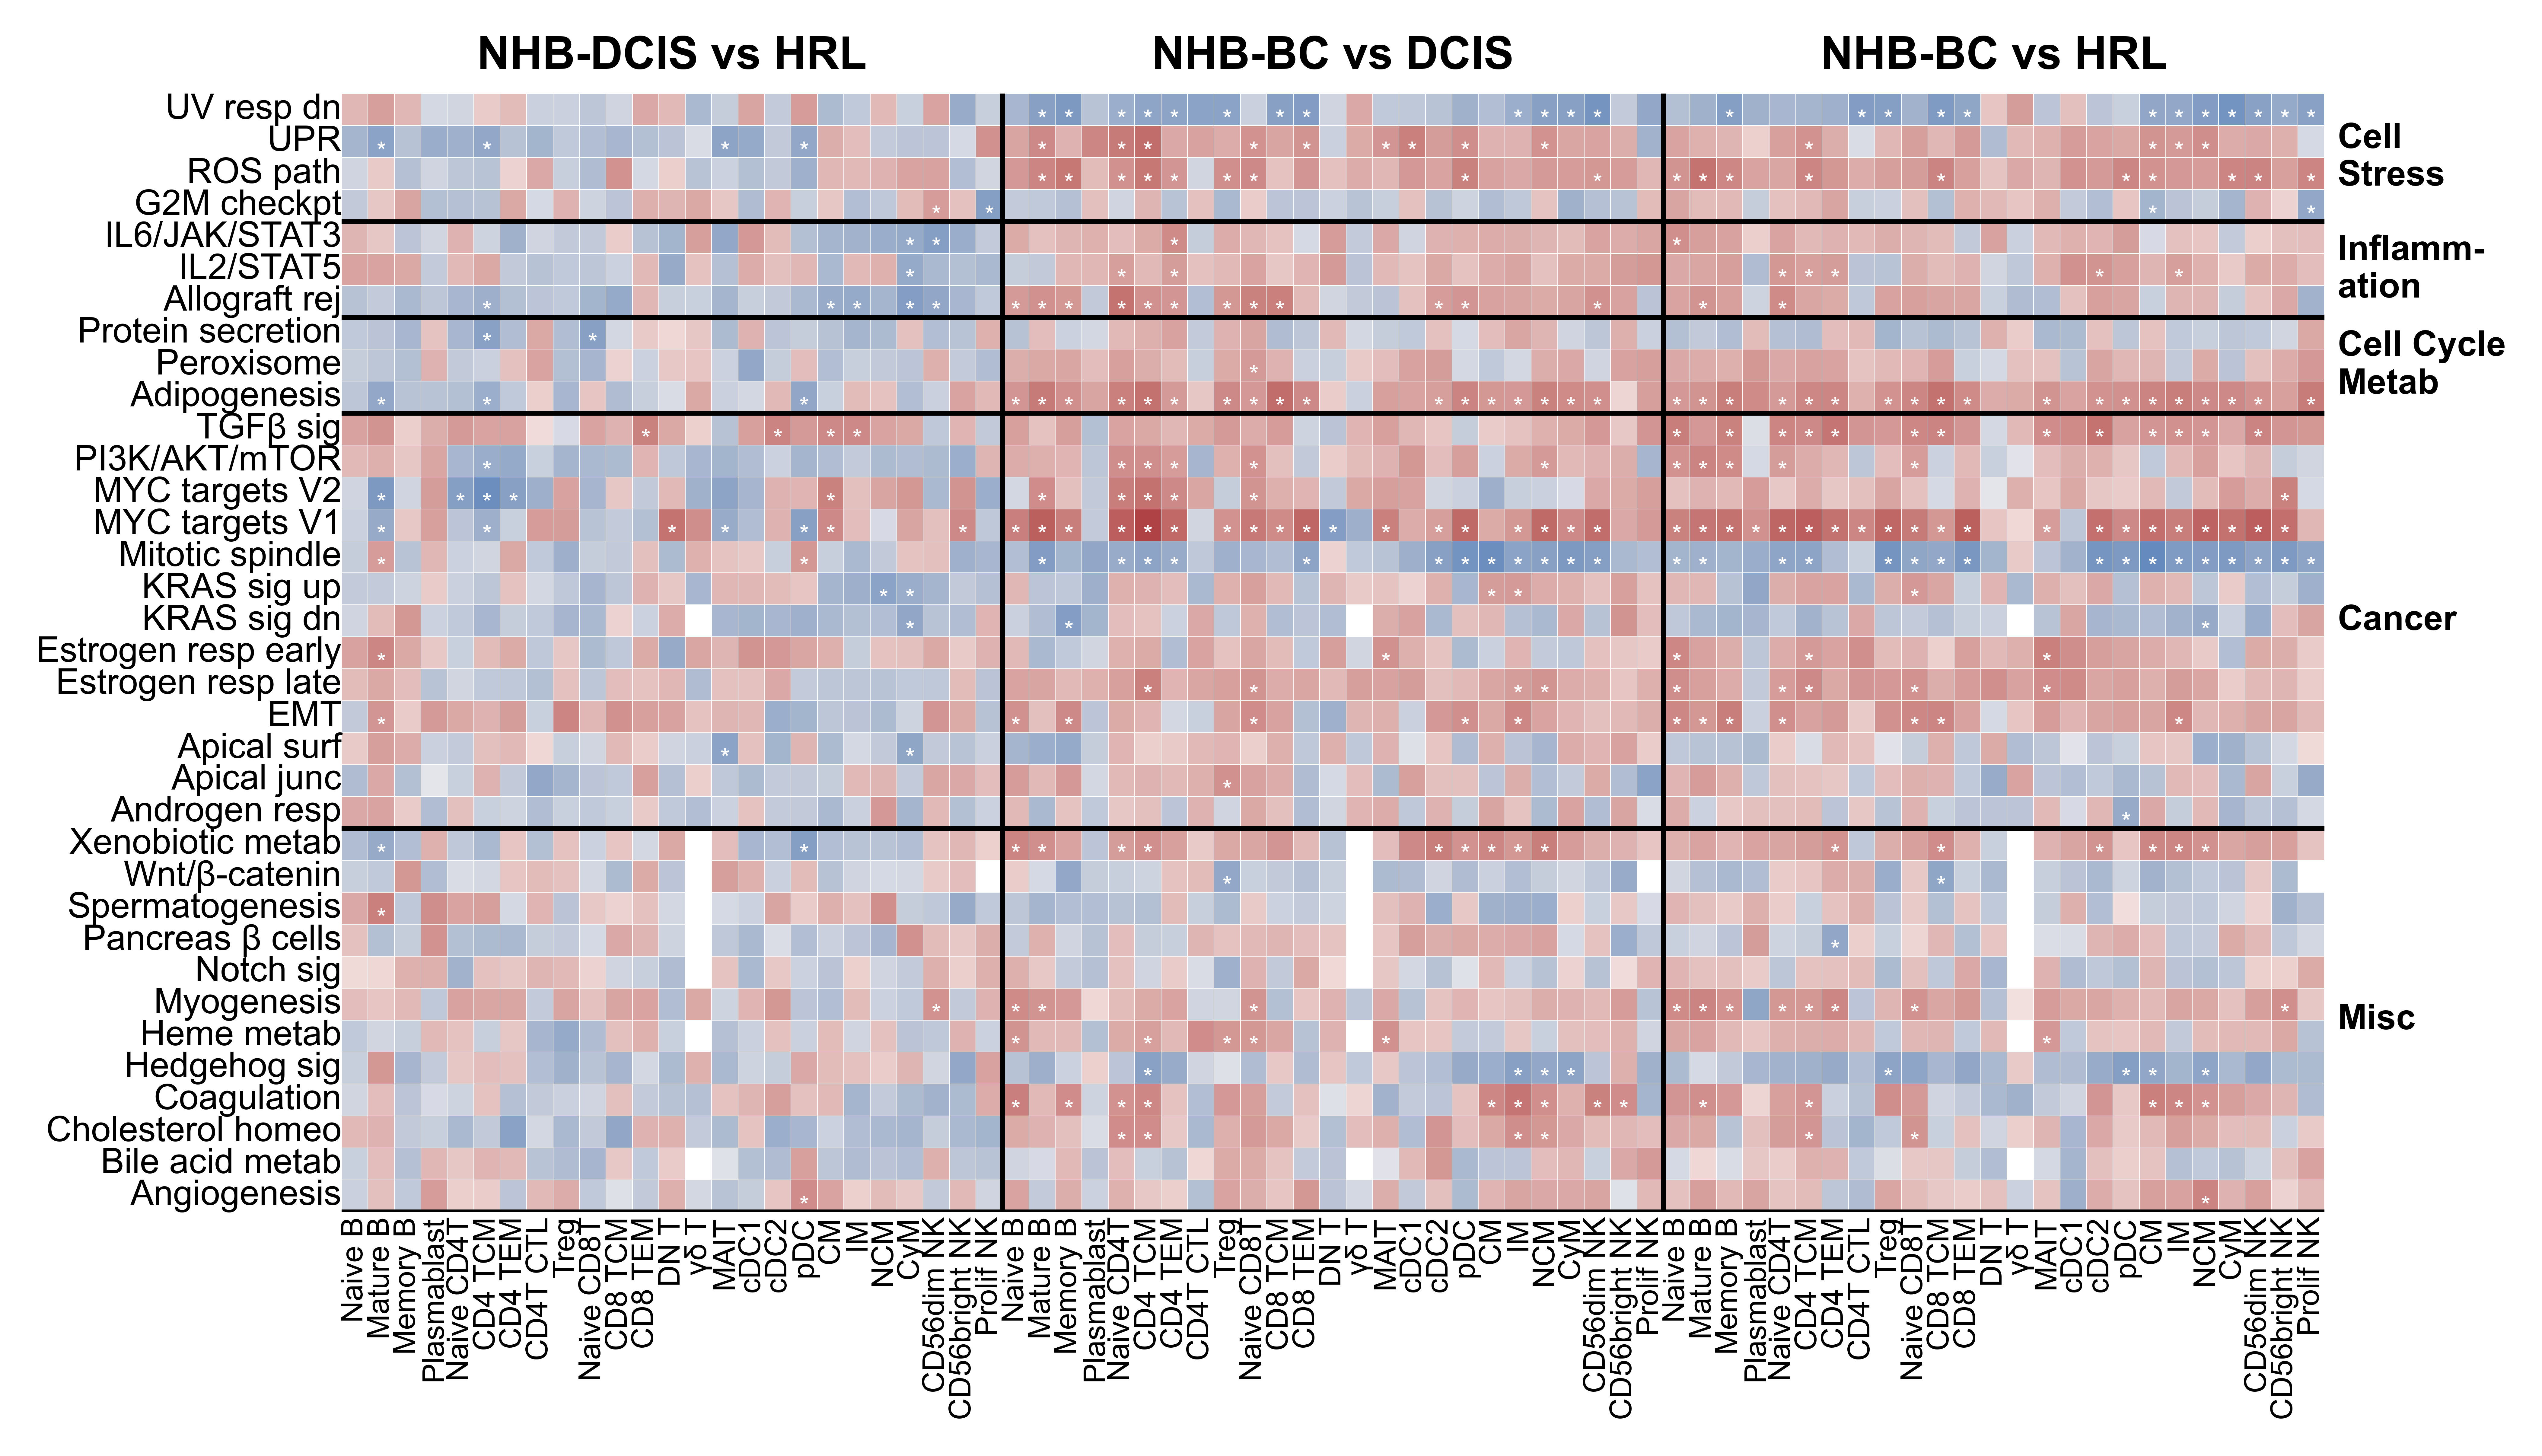

In [18]:
# 2. Create annotation matrix for significance (* if padj < 0.1)

mat_nes_sel = mat_nes.loc[rows_sel, cols_sel]
mat_pdj_sel = mat_pdj.loc[rows_sel, cols_sel]


plt_major_celltype={'B': '#3072C4',
  'T': '#EF763F',
  'DC': '#35A293',
  'Mono': '#B3813E',
  'NK': '#7D4C99'}


colors = sns.color_palette("Paired")
hex_colors = colors.as_hex()

group_palette = {
    # NHW comparisons - cold colors
    # 'NHW-DCIS vs HRL': hex_colors[0],  # light sky blue
    # 'NHW-BC vs HRL':   hex_colors[2],  # deep navy blue
    # 'NHW-BC vs DCIS':  hex_colors[4],  # vivid cyan-teal

    # NHB comparisons - warm colors
    'NHB-DCIS vs HRL': hex_colors[1],  # salmon pink
    'NHB-BC vs HRL':   hex_colors[3],  # deep crimson red
    'NHB-BC vs DCIS':  hex_colors[5]   # vivid orange
}


annot = mat_pdj_sel.applymap(lambda v: '*' if v < 0.05 else '')

# 3. Build celltype color map for x-axis labels
celltype_colors = []
celltype_labels = []
for label in mat_nes_sel.columns:
    # Extract celltype from xlabel (after '___')
    celltype = label.split('___')[1]
    celltype_labels.append(celltype)
    # Identify major group
    group_color = None
    for group, types in cells_group.items():
        if celltype in types:
            group_color = plt_major_celltype[group]
            break
    celltype_colors.append(group_color if group_color else 'black')

# 4. Plot heatmap
fig, ax = plt.subplots(figsize=(7,4))
ax.tick_params(axis='y', length=0)
ax.tick_params(axis='y', pad=0)
ax.tick_params(axis='x', length=0)
ax.tick_params(axis='x', pad=1)

hm = sns.heatmap(
    mat_nes_sel,
    ax=ax,
    cmap='vlag',
    center=0,
    vmin = -3,
    vmax = 3,
    annot=annot,
    linecolor='white',
    linewidth=.01,
    fmt='',
    cbar_kws={"shrink": 0.2, "pad": 0.04, "orientation": "horizontal"},
    annot_kws={"va": "top", "ha": "center", "fontsize": 5, "color": "white"}
)

hm.collections[0].colorbar.remove() # remove cbar

# 5. Format y-axis: show all pathways
ax.set_yticks(np.arange(len(mat_nes_sel)) + 0.5)
ax.set_yticklabels([pathway_short_dict[x] for x in mat_nes_sel.index], rotation=0, fontsize=7)

# 6. Format x-axis: show celltype names, rotate, bold, colored
celltype_labels_short = [
    celltype_short.get(x, x) for x in celltype_labels
]

ax.set_xticks(np.arange(len(mat_nes_sel.columns)) + 0.5)
ax.set_xticklabels(
    celltype_labels_short,
    rotation=90,
    fontweight="regular",
    fontsize=6
)

# for xtick, color in zip(ax.get_xticklabels(), celltype_colors):
#     xtick.set_color(color)

# 7. Add thick horizontal separation lines by pathway groups
pathway_groups = {
    'Cell Stress': other_Cell_stress,
    'Inflammation': other_Inflammation,
    'Cell Cycle\nMetabolism': other_Cell_cycle_metabolism,
    'Cancer': other_Cancer,
    'Miscellaneous': other_Miscellaneous
}
y_pos = 0
for group, pathways in pathway_groups.items():
    y_pos += len(pathways)
    if y_pos < len(mat_nes):
        ax.axhline(y=y_pos, color='black', linewidth=1)

# 8. Add thick vertical separation lines by subgroup
x_pos = 0
current_subgroup = mat_nes_sel.columns[0].split('___')[0]
for i, col in enumerate(mat_nes_sel.columns):
    subgroup = col.split('___')[0]
    if subgroup != current_subgroup:
        ax.axvline(x=i, color='black', linewidth=1)  # vertical line before new subgroup
        current_subgroup = subgroup
        
plt.xlabel('')
plt.ylabel('')

# 10. Add subgroup titles on top of each subgroup block
subgroup_positions = []
current_subgroup = mat_nes_sel.columns[0].split('___')[0]
start_idx = 0

for i, col in enumerate(mat_nes_sel.columns):
    subgroup = col.split('___')[0]
    if subgroup != current_subgroup:
        mid_pos = (start_idx + i) / 2.0
        subgroup_positions.append((current_subgroup, mid_pos))
        current_subgroup = subgroup
        start_idx = i

## Append the last subgroup
mid_pos = (start_idx + len(mat_nes_sel.columns)) / 2.0
subgroup_positions.append((current_subgroup, mid_pos))


for subgroup, mid_pos in subgroup_positions:
    color = 'black'#group_palette.get(subgroup, 'black')
    ax.text(
        mid_pos,        # center position
        -0.5,           # just above x-axis
        subgroup,
        color=color,
        ha='center',
        va='bottom',
        fontweight='bold',
        fontsize=9,
        transform=ax.transData
    )
    

# 11. Add pathway group labels on the right side of y-axis
y_pos = 0
for group_name, pathways in pathway_groups.items():
    block_size = len(pathways)
    mid_y = y_pos + block_size / 2.0  # center of the block
    
    group_name_formatted = {
        'Cell Stress':'Cell\nStress',
        'Inflammation':'Inflamm-\nation',
        'Cell Cycle\nMetabolism': 'Cell Cycle\nMetab',
        'Cancer':'Cancer',
        'Miscellaneous':'Misc'
    }
    
    ax.text(
        len(mat_nes_sel.columns) + .5,  # place outside heatmap (right side)
        mid_y,
        group_name_formatted.get(group_name, group_name),
        color='black',
        ha='left',
        va='center',
        fontweight='bold',
        fontsize=7,
        rotation=0,
        clip_on=False,
        transform=ax.transData
    )

    y_pos += block_size
    
plt.tight_layout()
plt.savefig('plots/S3/RRE_heatmap_bystageNHB_hallmark.svg')